# 미션 5_오토인코더 문서 복원 · 심전도 이상 탐지

오토인코더(AutoEncoder)로 **손상된 스캔 문서 복원**과 **심전도 이상 탐지** 두 문제 해결.

<img src="images/m5_map.png" alt="미션 5 학습 지도: 준비 · 문서 복원 · 이상 탐지 · 마무리" width="973">

**단계별 구성**: 한글 요약 → 실행 흐름 → 코드(이유 주석) → 실행 결과 → 결과 해설 → 소속별 최종 요약표

**평가 원칙**
- 문서 복원: 패치가 아닌 **전체 이미지 RMSE**로 평가 (Kaggle 채점 방식)
- 학습 없이 얻는 **기준선 3종**과 비교해 학습 효과 확인
- 이상 탐지 임계값: **보정용 데이터에서 결정 → 따로 떼어 둔 평가 데이터에서 확인**

## 🎯 학습 목표

이 미션을 마치면 다음을 직접 할 수 있어야 함

1. 학습 없는 **기준선**을 먼저 계산해 모델이 실제로 배웠는지 판단한다
2. 병목 크기 · 스킵 연결이 다른 오토인코더를 **같은 조건**(패치 · epoch · 조기 종료)에서 비교한다
3. 패치로 학습하고 **전체 이미지**로 평가하는 흐름을 패딩 · 자르기로 구현한다
4. 정상 데이터만 학습한 순환 오토인코더의 **복원 오차**를 이상 점수로 쓴다
5. 라벨 없는 임계값과 보정 데이터로 고른 임계값을 **따로 떼어 둔 평가 데이터**에서 비교한다

## 🧭 활용처

- **문서 디지털화**: 스캔 문서의 얼룩 · 구김 제거 후 OCR 정확도 향상
- **설비 · 의료 모니터링**: 정상 데이터만 많고 이상은 드문 센서 · 심전도 신호의 이상 탐지
- **이미지 복원 일반**: 노이즈 제거 · 업스케일링처럼 입력과 출력 크기가 같은 문제

## 핵심 결과

- 문서 복원: **U-Net 검증 RMSE 0.0156**, 학습 없는 최선의 기준선(0.0836) 대비 **5.4배** 개선
- 이상 탐지: **GRU 오토인코더 ROC-AUC 0.959**, 보정한 임계값으로 재현율 0.934 · F1 0.945

### 데이터 구성

- **1. 문서 복원**: Kaggle [*Denoising Dirty Documents*](https://www.kaggle.com/competitions/denoising-dirty-documents), `train`(손상) · `train_cleaned`(정답) **144쌍**, 정답 없는 `test` 72장, 가로 540px · 세로 420px 또는 258px
- **2. 이상 탐지**: ECG5000, 심전도 **4,998개** × 140 스텝, 마지막 열 = 라벨 (0 = 이상)
- **실행 환경**: 대회 압축 파일 `denoising-dirty-documents.zip`을 노트북 폴더에 두면 처음 한 번 자동 해제, ECG5000은 처음 실행 때 내려받아 `ecg.csv`로 저장

---
## 0. 준비

### 0-1. 환경 설정과 공통 함수

**한글 요약**

이미지 · 딥러닝 · 평가 라이브러리를 불러오고, 한글 폰트와 그래프 색 통일. 모든 실험이 같은 난수 조건에서 시작하도록 **난수 고정 함수**, RMSE 그래프용 **로그 축 표기 함수** 정의.

**실행 흐름**

1. **입력**: 설치된 라이브러리 · 폰트
2. **처리**: 라이브러리 불러오기 → 한글 폰트 · 그래프 색 → 시드 · 장치(GPU) 설정 → 난수 고정 · 로그 축 함수 정의
3. **저장**: `SEED` · `device` · `seed_all` · `plain_log`, 공통 색
4. **출력**: 학습 장치 이름

In [1]:
# 라이브러리 불러오기
import copy  # 최고 성능 시점의 가중치를 따로 보관하기 위해
import time  # 모델별 학습 시간을 재기 위해
import zipfile  # Kaggle 압축 파일을 풀기 위해
from pathlib import Path  # 운영체제와 상관없이 경로를 다루기 위해
import matplotlib.pyplot as plt  # 그래프를 그리기 위해
import numpy as np  # 난수 · 배열 계산을 위해
import pandas as pd  # 결과를 표로 정리하기 위해
import torch  # 텐서 연산 · GPU 학습을 위해
import torch.nn as nn  # 신경망 층을 쓰기 위해
import torch.nn.functional as F  # 손실 · 패딩 같은 함수형 연산을 쓰기 위해
import torchvision.transforms.functional as TF  # 이미지 → 텐서 변환, 회전 · 밝기 증강을 위해
from IPython.display import display  # 셀 중간에 표를 출력하기 위해
from matplotlib import font_manager  # 설치된 한글 폰트를 찾기 위해
from matplotlib.ticker import FuncFormatter  # 로그 축 눈금을 일반 숫자로 보이기 위해
from PIL import Image  # PNG 이미지를 읽기 위해
from sklearn.metrics import f1_score, precision_score, recall_score, roc_auc_score, roc_curve, balanced_accuracy_score  # 이상 탐지 성능을 여러 지표로 보기 위해
from sklearn.model_selection import train_test_split  # 학습 · 검증으로 나누기 위해
from torch.utils.data import DataLoader, Dataset, TensorDataset  # 미니배치로 공급하기 위해

# 그래프 스타일
installed = {f.name for f in font_manager.fontManager.ttflist}  # 설치된 폰트를 빠르게 찾기 위해
for font in ["Malgun Gothic", "AppleGothic", "NanumGothic"]:  # Windows → macOS → Linux 어디서든 한글이 보이도록
    if font in installed:  # 설치된 첫 한글 폰트를 쓰기 위해
        plt.rcParams["font.family"] = font  # 그래프 한글 깨짐을 막기 위해
        break  # 하나만 적용하기 위해
plt.rcParams["axes.unicode_minus"] = False  # 한글 폰트에서 마이너스 기호가 깨지지 않도록
BLUE, RED, GRAY, GREEN = "#2a78d6", "#d03b3b", "#9a9890", "#2ca25f"  # 모든 그래프의 의미를 같은 색으로 맞추기 위해 (기본 · 강조 · 기준선 · 임계값)

# 시드 · 장치 설정
SEED = 42  # 분할 · 초기화 · 셔플 결과를 재현하기 위해
device = "cuda" if torch.cuda.is_available() else "cpu"  # GPU가 있으면 학습을 빠르게 하기 위해
print("device:", device, "|", torch.cuda.get_device_name(0) if device == "cuda" else "CPU")  # 학습 장치를 확인하기 위해

# 난수 고정 함수
def seed_all(seed=SEED):  # 모든 실험을 같은 난수 조건에서 시작하기 위해
    """numpy · torch(CPU · GPU) 난수 고정"""
    np.random.seed(seed)  # 패치 위치 · 증강 난수를 고정하기 위해
    torch.manual_seed(seed)  # 가중치 초기화 난수를 고정하기 위해
    torch.cuda.manual_seed_all(seed)  # GPU 난수도 고정하기 위해

# 로그 축 표기 함수
def plain_log(ax):  # RMSE 그래프마다 같은 설정을 반복하지 않도록
    """로그 축 눈금을 1e-2 대신 0.01처럼 일반 숫자로 표시"""
    ax.set_yscale("log")  # 기준선 · 모델 RMSE 차이가 10배 이상이라 한 그래프에 담기 위해
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))  # 주 눈금을 일반 숫자로 읽기 쉽게 하기 위해
    ax.yaxis.set_minor_formatter(FuncFormatter(lambda v, _: f"{v:g}" if str(v)[0] in "25" else ""))  # 보조 눈금이 겹치지 않도록 2 · 5로 시작하는 값만 표시

device: cuda | NVIDIA GeForce RTX 3060


**결과 해설**

```
device: cuda | NVIDIA GeForce RTX 3060 : GPU로 학습 · 추론
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| seed_all() · plain_log() | 사용자 정의 함수 | 난수 한 번에 고정 · 로그 축 눈금 | `def seed_all(seed=SEED):` |
| cuda.is_available() · manual_seed() · cuda.manual_seed_all() | torch | GPU 여부 · CPU · GPU 난수 고정 | `torch.cuda.manual_seed_all(seed)` |
| random.seed() | numpy | numpy 난수 고정 | `np.random.seed(seed)` |
| rcParams · set_yscale() · FuncFormatter() | matplotlib | 전역 설정 · 로그 축 · 눈금 변환 | `ax.yaxis.set_major_formatter(...)` |
| print() · str() | Python 내장 함수 | 장치 출력 · 첫 글자 확인 | `str(v)[0] in "25"` |
| import · def · lambda · 조건 표현식 | Python 기본 문법 | 불러오기 · 함수 · 한 줄 함수 · 값 선택 | `"cuda" if ... else "cpu"` |

---
## 1. 손상된 문서 복원

### 1-1. 데이터 불러오기와 학습 · 검증 분할

**한글 요약**

- [Kaggle 대회 페이지](https://www.kaggle.com/competitions/denoising-dirty-documents)에서 받은 `denoising-dirty-documents.zip`을 노트북 폴더에 두면 처음 한 번 자동 압축 해제
- 모든 PNG를 0~1 범위 흑백 텐서로 메모리에 적재 (이미지 수가 적어 매번 디스크에서 읽지 않음)
- 세로 크기 2종(420px · 258px)의 **비율을 유지한 채** 학습 115장 · 검증 29장으로 분할

**실행 흐름**

1. **입력**: `denoising-dirty-documents.zip`
2. **처리**: 압축 해제(처음 한 번) → 손상 · 정답 · test 이미지 텐서 변환 → 세로 크기 기준 층화 분할 → 겹침 검사
3. **저장**: `dirty` · `clean` · `test_imgs` · `train_files` · `val_files`
4. **출력**: 데이터 규모, 세로 크기 × 분할 교차표

In [2]:
# 압축 해제
DATA = Path("data")  # 압축을 풀 폴더를 한 곳으로 정하기 위해
if not (DATA / "train").exists():  # 두 번째 실행부터는 다시 풀지 않도록
    with zipfile.ZipFile("denoising-dirty-documents.zip") as z:  # 대회 전체 압축 파일을 열기 위해
        z.extractall(DATA)  # 안쪽 zip 파일을 꺼내기 위해
    for part in ["train", "train_cleaned", "test"]:  # 손상 · 정답 · 채점용 폴더를 모두 풀기 위해
        with zipfile.ZipFile(DATA / f"{part}.zip") as z:  # 폴더별 압축 파일을 열기 위해
            z.extractall(DATA)  # PNG를 꺼내기 위해

# 이미지 불러오기 함수
def load_dir(folder):  # 세 폴더를 같은 방식으로 읽기 위해
    """폴더의 PNG → {파일 이름: 0~1 범위 흑백 텐서 (1, H, W)}"""
    return {p.name: TF.to_tensor(Image.open(p).convert("L")) for p in sorted((DATA / folder).glob("*.png"))}  # 파일 이름으로 바로 찾도록 이름순 딕셔너리

# 데이터 불러오기 · 분할
dirty, clean, test_imgs = load_dir("train"), load_dir("train_cleaned"), load_dir("test")  # 손상 입력 · 정답 · 정답 없는 test를 메모리에 올리기 위해
files = sorted(dirty)  # 실행마다 같은 순서로 분할하기 위해
heights = [dirty[f].shape[1] for f in files]  # 세로 크기(258 또는 420) 비율을 유지해 나누기 위해
train_files, val_files = train_test_split(files, test_size=0.2, stratify=heights, random_state=SEED)  # 두 크기를 학습 · 검증에 같은 비율로 배분하기 위해

# 분할 결과 확인
assert set(train_files).isdisjoint(val_files)  # 학습 · 검증 이미지가 겹치지 않도록
size_table = pd.crosstab(pd.Series(heights, name="세로 크기"),
                         pd.Series(["검증" if f in val_files else "학습" for f in files], name="분할"), margins=True, margins_name="합계")  # 크기 비율이 유지됐는지 개수로 보기 위해
print(f"학습 쌍 {len(files)}장 (학습 {len(train_files)} · 검증 {len(val_files)}) · 정답 없는 test {len(test_imgs)}장 · 가로는 모두 540px")  # 데이터 규모를 확인하기 위해
size_table  # 크기 비율 유지를 표로 확인하기 위해

학습 쌍 144장 (학습 115 · 검증 29) · 정답 없는 test 72장 · 가로는 모두 540px


분할,검증,학습,합계
세로 크기,,,
258,10,38,48
420,19,77,96
합계,29,115,144


**결과 해설**

```
학습 쌍 144장                 : 학습 115장 · 검증 29장 (8:2), assert로 겹침 없음 확인
258px 38 · 10 / 420px 77 · 19 : 두 크기 모두 학습 · 검증에 같은 비율로 배분
test 72장                     : 정답 없음 → 복원 예시(1-8)에만 사용
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| load_dir() | 사용자 정의 함수 | 폴더 PNG → 텐서 딕셔너리 | `load_dir("train")` |
| Path() · exists() · glob() | pathlib | 경로 · 존재 확인 · PNG 목록 | `(DATA / "train").exists()` |
| ZipFile() · extractall() | zipfile | 압축 열기 · 전체 해제 | `z.extractall(DATA)` |
| Image.open() · convert() · to_tensor() | PIL · torchvision | PNG 읽기 · 흑백 · 0~1 텐서 | `TF.to_tensor(Image.open(p).convert("L"))` |
| train_test_split() · crosstab() | sklearn · pandas | 크기 비율 유지 분할 · 교차표 | `train_test_split(files, test_size=0.2, stratify=heights, ...)` |
| sorted() · set() · isdisjoint() | Python 내장 함수 | 정렬 · 집합 · 겹침 없음 | `set(train_files).isdisjoint(val_files)` |
| with · 컴프리헨션 · assert | Python 기본 문법 | 파일 자동 닫기 · 한 줄 생성 · 검증 | `with zipfile.ZipFile(...) as z:` |

### 1-2. 손상 입력과 정답 확인

**한글 요약**

검증 첫 이미지의 손상 입력과 정답을 나란히 표시해 **손상 유형** 확인.

**실행 흐름**

1. **입력**: 검증 첫 이미지
2. **처리**: 1행 2열 그림 → 손상 입력 · 정답 흑백 표시
3. **저장**: 없음
4. **출력**: 손상 입력 · 정답 그림

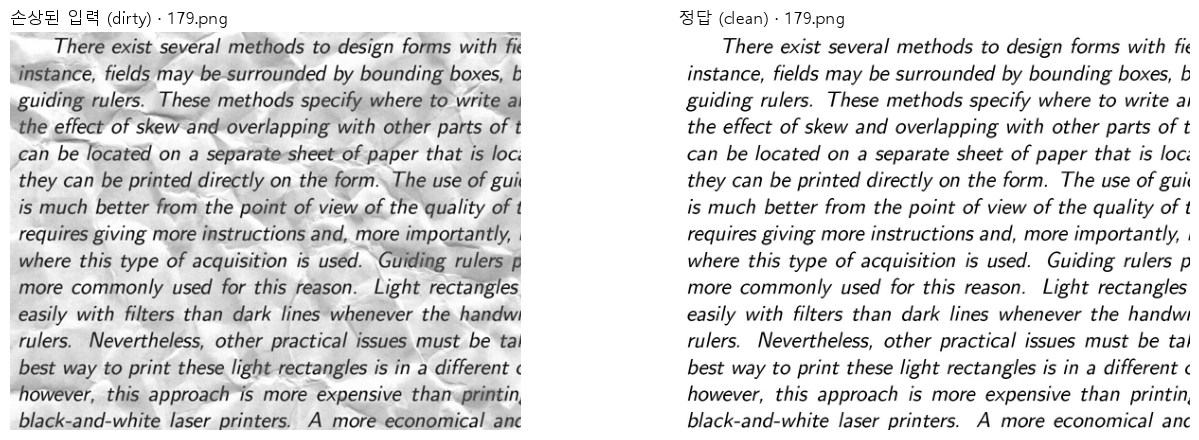

In [3]:
# 손상 입력 · 정답 나란히 표시
sample = val_files[0]  # 학습에 쓰지 않은 검증 이미지로 보기 위해
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))  # 입력과 정답을 나란히 비교하기 위해
for ax, img, title in zip(axes, [dirty[sample], clean[sample]], ["손상된 입력 (dirty)", "정답 (clean)"]):  # 칸 · 이미지 · 제목을 짝지어 그리기 위해
    ax.imshow(img.squeeze(), cmap="gray", vmin=0, vmax=1)  # 두 이미지의 밝기 기준을 0~1로 같게 하기 위해
    ax.set_title(f"{title} · {sample}", loc="left")  # 어떤 이미지인지 알리기 위해
    ax.axis("off")  # 문서만 보이도록 눈금 숨김
plt.tight_layout()  # 여백을 자동으로 맞추기 위해
plt.show()  # 그림을 출력하기 위해

**결과 해설**

```
손상된 입력 : 종이 전체의 구김 그림자 → 배경 밝기가 고르지 않음
정답        : 흰 배경 + 검은 글자만 남은 깨끗한 문서
```

- 구김 그림자는 넓고 천천히 변하는 반면 글자는 가늘고 날카로움 → 이 차이가 기준선(1-3)과 모델의 핵심 단서

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| squeeze() | torch.Tensor | 크기 1인 채널 차원 제거 | `img.squeeze()` |
| subplots() · imshow() · set_title() · axis() | matplotlib | 그림 칸 · 흑백 표시 · 제목 · 눈금 숨김 | `ax.imshow(..., cmap="gray", vmin=0, vmax=1)` |
| for ... in zip() | Python 기본 문법 | 칸 · 이미지 · 제목 짝지어 반복 | `for ax, img, title in zip(...):` |

### 1-3. 평가 지표와 학습 없는 기준선

**한글 요약**

- **지표**: 검증 이미지의 모든 픽셀을 모아 계산한 RMSE (Kaggle 채점 방식) + 이미지별 PSNR 평균
- **기준선**: 모델이 실제로 무언가를 배웠는지 판단하기 위한 비교 대상, 학습 없이 얻는 방법 3종을 먼저 계산

**실행 흐름**

1. **입력**: 검증 29장
2. **처리**: 중간값 필터 함수 → 기준선 3종(그대로 · 전부 흰색 · 배경 제거) → 전체 이미지 평가 함수 → 기준선 평가
3. **저장**: `median_filter` · `BASELINES` · `evaluate` · `baseline_scores`
4. **출력**: 기준선별 RMSE · PSNR 표

In [4]:
# 중간값 필터 함수
def median_filter(x, window):  # 넓은 범위의 배경 밝기를 추정하기 위해
    """(N, 1, H, W) 텐서의 window × window 중간값 필터 (가장자리는 복제 패딩)"""
    r = window // 2  # 패딩 폭을 정하기 위해 창 반지름
    n, c, h, w = x.shape  # 결과를 원래 모양으로 되돌리기 위해 크기 기억
    patches = F.unfold(F.pad(x, (r, r, r, r), mode="replicate"), window)  # 픽셀마다 주변 window × window 값을 펼쳐 한 번에 계산하기 위해
    return patches.median(dim=1).values.view(n, c, h, w)  # 주변 값의 중간값을 원래 모양으로 돌려주기 위해

# 학습 없는 기준선 3종
BASELINES = {
    "입력 그대로 (identity)": lambda x: x,  # 아무 처리도 안 했을 때의 오차를 출발점으로 삼기 위해
    "전부 흰색 (all white)": lambda x: torch.ones_like(x),  # 배경이 대부분 흰색이라는 점만 이용했을 때와 비교하기 위해
    "중간값 배경 제거 (median 23)": lambda x: (1 + x - median_filter(x, 23)).clamp(0, 1),  # 넓은 창 중간값을 배경으로 보고 빼서 얼룩을 지우기 위해
}

# 전체 이미지 평가 함수
@torch.no_grad()  # 평가에는 기울기가 필요 없어 메모리를 아끼기 위해
def evaluate(fn, names, src=dirty, ref=clean):  # 기준선과 모델을 같은 방식으로 평가하기 위해
    """전체 이미지 단위 평가: 픽셀을 모두 모은 RMSE + 이미지별 PSNR 평균"""
    sq_sum, n_pix, psnrs = 0.0, 0, []  # 전체 RMSE와 이미지별 PSNR을 모으기 위해
    for name in names:  # 이미지를 한 장씩 평가하기 위해
        x, y = src[name].unsqueeze(0).to(device), ref[name].unsqueeze(0).to(device)  # 모델 입력 모양으로 바꿔 GPU로 보내기 위해
        out = fn(x)  # 복원 결과를 얻기 위해
        mse = ((out - y) ** 2).mean().item()  # PSNR 계산에 쓸 이미지 1장 MSE
        sq_sum += ((out - y) ** 2).sum().item()  # Kaggle 방식 RMSE를 위해 제곱 오차를 누적
        n_pix += y.numel()  # 픽셀 수로 나누기 위해 누적
        psnrs.append(10 * np.log10(1 / max(mse, 1e-10)))  # 0으로 나누지 않도록 하한을 두고 PSNR(dB) 계산
    return {"RMSE": (sq_sum / n_pix) ** 0.5, "PSNR(dB)": float(np.mean(psnrs))}  # 큰 이미지일수록 픽셀 수만큼 크게 반영되도록

# 기준선 평가
baseline_scores = {name: evaluate(fn, val_files) for name, fn in BASELINES.items()}  # 모델과 같은 검증 29장으로 비교하기 위해
pd.DataFrame(baseline_scores).T.style.format({"RMSE": "{:.4f}", "PSNR(dB)": "{:.2f}"})  # 기준선별 한 행으로 보기 위해

,RMSE,PSNR(dB)
입력 그대로 (identity),0.1515,16.54
전부 흰색 (all white),0.2941,10.76
중간값 배경 제거 (median 23),0.0836,21.66


**결과 해설**

```
입력 그대로 0.1515      : 손상 그대로일 때의 오차 (출발점)
전부 흰색 0.2941        : 글자까지 지워 오히려 악화
중간값 배경 제거 0.0836 : 학습 없이 얻은 최선, PSNR 16.54 → 21.66 dB
```

- 넓은 얼룩은 배경처럼 천천히 변하고 글자는 가늘어, **중간값 필터로 배경을 추정해 빼는 것**만으로 RMSE 크게 감소
- 모델은 **최소한 0.0836보다 좋아야** 학습한 의미가 있음

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| median_filter() · evaluate() | 사용자 정의 함수 | 중간값 필터 · 전체 이미지 RMSE · PSNR | `evaluate(fn, val_files)` |
| no_grad() · ones_like() | torch | 기울기 끄기 · 흰색 텐서 | `@torch.no_grad()` |
| pad() · unfold() | torch.nn.functional | 복제 패딩 · 주변 픽셀 펼치기 | `F.unfold(F.pad(x, ..., mode="replicate"), window)` |
| median() · view() · clamp() · numel() | torch.Tensor | 중간값 · 모양 · 0~1 자르기 · 픽셀 수 | `.clamp(0, 1)` · `y.numel()` |
| log10() · mean() | numpy | PSNR · 평균 | `np.log10(1 / ...)` |
| @ 데코레이터 · lambda · += | Python 기본 문법 | 기능 덧씌우기 · 한 줄 함수 · 누적 | `sq_sum += ...` |

### 1-4. 비교할 모델 · 패치 데이터셋

**한글 요약**

- 학습은 이미지에서 잘라 낸 **패치**로, 평가는 **전체 이미지**로
- 증강 실험에서만 작은 회전(±3도) · 밝기/대비 변화(±10%) 적용, 회전은 입력 · 정답에 같은 각도로

<img src="images/m5_patch.png" alt="패치로 학습하고 전체 이미지로 평가하는 흐름" width="837">

**실행 흐름**

1. **입력**: `dirty` · `clean`, 이미지 이름 목록
2. **처리**: 같은 위치 무작위 패치 자르기 → 선택적 증강(회전 · 밝기 · 대비)
3. **저장**: `PatchDataset` 클래스
4. **출력**: 없음 (정의 셀)

In [5]:
# 패치 데이터셋
class PatchDataset(Dataset):  # DataLoader가 패치 쌍을 꺼내 쓰도록
    """손상 · 정답 이미지에서 같은 위치의 패치를 잘라 쌍으로 반환"""
    def __init__(self, names, patch, repeats, augment=False):  # 실험마다 패치 크기 · 증강을 바꾸기 위해
        self.names, self.patch, self.repeats, self.augment = names, patch, repeats, augment  # 이미지 목록 · 패치 크기 · 이미지당 패치 수 · 증강 여부를 기억하기 위해
    def __len__(self):  # epoch당 패치 수를 알려 주기 위해
        return len(self.names) * self.repeats  # 이미지마다 repeats개씩 뽑기 위해
    def __getitem__(self, idx):  # 패치 하나를 만들기 위해
        name = self.names[idx // self.repeats]  # 같은 이미지에서 repeats번 추출하기 위해
        x, y = dirty[name], clean[name]  # 손상 입력과 정답을 함께 쓰기 위해
        _, h, w = x.shape  # 패치가 이미지를 벗어나지 않도록 크기 확인
        top, left = np.random.randint(0, h - self.patch + 1), np.random.randint(0, w - self.patch + 1)  # 매번 다른 위치를 배우도록 무작위 위치
        x, y = x[:, top:top + self.patch, left:left + self.patch], y[:, top:top + self.patch, left:left + self.patch]  # 입력 · 정답을 같은 위치로 자르기 위해
        if self.augment:  # 증강 실험에서만 적용하기 위해
            if np.random.rand() < 0.5:  # 스캔 기울어짐을 50% 확률로 흉내 내기 위해
                angle = float(np.random.uniform(-3, 3))  # 글자가 크게 변형되지 않도록 -3 ~ 3도만
                x = TF.rotate(x, angle, fill=[1.0])  # 빈 곳을 흰 종이로 채우기 위해
                y = TF.rotate(y, angle, fill=[1.0])  # 정답도 같은 각도로 맞추기 위해
            if np.random.rand() < 0.3:  # 조명 차이를 30% 확률로 흉내 내기 위해 (입력에만)
                x = TF.adjust_contrast(TF.adjust_brightness(x, float(np.random.uniform(0.9, 1.1))), float(np.random.uniform(0.9, 1.1)))  # 밝기 · 대비를 ±10% 바꾸기 위해
        return x, y  # 입력 · 정답 쌍을 돌려주기 위해

**결과 해설**

```
출력 없음 : 패치 데이터셋 정의, 1-5 학습에서 사용
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| PatchDataset | 사용자 정의 클래스 | 패치 쌍 공급 | `PatchDataset(train_files, patch, ...)` |
| Dataset | torch.utils.data | 사용자 데이터셋 부모 클래스 | `class PatchDataset(Dataset):` |
| rotate() · adjust_brightness() · adjust_contrast() | torchvision.transforms.functional | 회전 · 밝기 · 대비 변화 | `TF.rotate(x, angle, fill=[1.0])` |
| random.randint() · random.rand() · random.uniform() | numpy | 무작위 위치 · 확률 · 각도 | `np.random.randint(0, h - self.patch + 1)` |
| class · __getitem__ · 슬라이싱 | Python 기본 문법 | 데이터셋 규칙 · 패치 자르기 | `x[:, top:top + self.patch, ...]` |

### 1-4. 비교할 모델 · 기본 AE와 넓은 병목 AE

**한글 요약**

- **기본 AE**: 인코더 2층(32 · 64채널) → 디코더 2층, 출발점이 되는 얕은 오토인코더
- **넓은 병목 AE**: 인코더 2층(64 · 256채널), 64px 패치, 층을 늘리는 대신 **채널을 넓혀** 정보 손실 감소

<img src="images/m5_ae.png" alt="기본 AE와 넓은 병목 AE의 층별 크기" width="837">

**실행 흐름**

1. **입력**: (1, H, W) 흑백 이미지
2. **처리**: stride 2 합성곱으로 크기 절반씩 압축 → 전치 합성곱으로 2배씩 복원
3. **저장**: `ShallowAE` · `WideAE` 클래스
4. **출력**: 없음 (정의 셀)

In [6]:
# 기본 AE
class ShallowAE(nn.Module):  # 가장 단순한 비교 기준을 만들기 위해
    """(1, H, W) → (32, H/2) → (64, H/4) → (32, H/2) → (1, H, W)"""
    multiple = 4  # 크기를 절반으로 2번 줄이므로 입력이 4의 배수여야 원래 크기로 돌아오기 때문
    def __init__(self):  # 인코더 · 디코더 층을 만들기 위해
        super().__init__()  # nn.Module 기본 설정을 먼저 실행하기 위해
        self.encoder = nn.Sequential(nn.Conv2d(1, 32, 3, 2, 1), nn.ReLU(), nn.Conv2d(32, 64, 3, 2, 1), nn.ReLU())  # stride 2로 크기를 절반씩 압축하기 위해
        self.decoder = nn.Sequential(nn.ConvTranspose2d(64, 32, 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(32, 1, 4, 2, 1), nn.Sigmoid())  # 크기를 2배씩 복원하고 출력을 0~1로 맞추기 위해
    def forward(self, x):  # model(x)로 호출할 때 실행되도록
        return self.decoder(self.encoder(x))  # 압축한 뒤 복원하기 위해

# 넓은 병목 AE
class WideAE(nn.Module):  # 채널 수만 바꿔 병목 정보량의 효과를 보기 위해
    """(1, H, W) → (64, H/2) → (256, H/4) → (64, H/2) → (1, H, W)"""
    multiple = 4  # 기본 AE와 같은 2층 구조이므로 같은 배수
    def __init__(self, chs=(64, 256)):  # 채널 수를 바꿔 실험할 수 있도록 인자로
        super().__init__()  # nn.Module 기본 설정을 먼저 실행하기 위해
        self.encoder = nn.Sequential(nn.Conv2d(1, chs[0], 3, 2, 1), nn.ReLU(), nn.Conv2d(chs[0], chs[1], 3, 2, 1), nn.ReLU())  # 채널만 넓혀 병목에 정보를 더 담기 위해
        self.decoder = nn.Sequential(nn.ConvTranspose2d(chs[1], chs[0], 4, 2, 1), nn.ReLU(), nn.ConvTranspose2d(chs[0], 1, 4, 2, 1), nn.Sigmoid())  # 크기를 2배씩 복원하고 출력을 0~1로 맞추기 위해
    def forward(self, x):  # model(x)로 호출할 때 실행되도록
        return self.decoder(self.encoder(x))  # 압축한 뒤 복원하기 위해

**결과 해설**

```
출력 없음 : 2층 오토인코더 2종 정의, 파라미터 수는 1-4 마지막 셀에서 확인
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| ShallowAE · WideAE | 사용자 정의 클래스 | 얕은 AE · 채널을 넓힌 AE | `ShallowAE()` · `WideAE()` |
| Module · Sequential | torch.nn | 모델 부모 클래스 · 층 묶음 | `nn.Sequential(...)` |
| Conv2d · ConvTranspose2d | torch.nn | 압축(크기 ↓) · 복원(크기 ↑) | `nn.Conv2d(1, 32, 3, 2, 1)` |
| ReLU · Sigmoid | torch.nn | 활성화 · 0~1 출력 | `nn.Sigmoid()` |
| 클래스 변수 · super() | Python 기본 문법 | 모델별 배수 기록 · 부모 초기화 | `multiple = 4` |

### 1-4. 비교할 모델 · U-Net

**한글 요약**

**U-Net**: 인코더 4층 + 병목, BatchNorm, **스킵 연결**. 인코더의 고해상도 특징을 디코더에 직접 전달해 글자 경계 보존.

<img src="images/m5_unet.png" alt="U-Net 인코더 · 병목 · 디코더와 스킵 연결" width="837">

**실행 흐름**

1. **입력**: (1, H, W) 흑백 이미지 (16의 배수 크기)
2. **처리**: 인코더 4층(크기 절반 · 채널 2배) → 병목 → 디코더(크기 2배) + 같은 해상도 인코더 특징 결합
3. **저장**: `conv_bn` · `up_bn` · `UNetAE`
4. **출력**: 없음 (정의 셀)

In [7]:
# U-Net 구성 블록
def conv_bn(cin, cout, stride=1):  # 같은 블록을 반복해서 만들기 위해
    return nn.Sequential(nn.Conv2d(cin, cout, 3, stride, 1), nn.BatchNorm2d(cout), nn.ReLU())  # 정규화로 학습을 안정시키기 위해 (stride 2면 크기 절반)
def up_bn(cin, cout):  # 디코더 블록을 반복해서 만들기 위해
    return nn.Sequential(nn.ConvTranspose2d(cin, cout, 4, 2, 1), nn.BatchNorm2d(cout), nn.ReLU())  # 전치 합성곱으로 크기를 2배로 키우기 위해

# U-Net
class UNetAE(nn.Module):  # 스킵 연결로 글자 경계를 보존하기 위해
    """해상도 128 → 64 → 32 → 16 → 8(병목) → 16 → 32 → 64 → 128, 같은 해상도끼리 스킵 연결(concat 후 conv)"""
    multiple = 16  # 크기를 절반으로 4번 줄이므로 16의 배수여야 하기 때문
    def __init__(self):  # 인코더 · 병목 · 디코더 층을 만들기 위해
        super().__init__()  # nn.Module 기본 설정을 먼저 실행하기 위해
        self.e1, self.e2, self.e3, self.e4 = conv_bn(1, 16), conv_bn(16, 32, 2), conv_bn(32, 64, 2), conv_bn(64, 128, 2)  # 인코더: 채널 2배 · 크기 절반씩 줄이기 위해
        self.bottleneck = nn.Sequential(nn.Conv2d(128, 256, 3, 2, 1), nn.ReLU())  # 가장 압축된 표현을 만들기 위해
        self.d4, self.d3, self.d2, self.d1 = up_bn(256, 128), up_bn(128, 64), up_bn(64, 32), up_bn(32, 16)  # 디코더: 크기를 2배씩 키우기 위해
        self.f4, self.f3, self.f2, self.f1 = conv_bn(256, 128), conv_bn(128, 64), conv_bn(64, 32), conv_bn(32, 16)  # 스킵 연결로 늘어난 채널을 정리하기 위해
        self.out = nn.Sequential(nn.Conv2d(16, 1, 3, 1, 1), nn.Sigmoid())  # 1채널 0~1 이미지로 내보내기 위해
    def forward(self, x):  # model(x)로 호출할 때 실행되도록
        e1 = self.e1(x)  # 128 × 128 (패치 기준), 스킵 연결에 쓰기 위해 보관
        e2 = self.e2(e1)  # 64 × 64, 스킵 연결에 쓰기 위해 보관
        e3 = self.e3(e2)  # 32 × 32, 스킵 연결에 쓰기 위해 보관
        e4 = self.e4(e3)  # 16 × 16, 스킵 연결에 쓰기 위해 보관
        d = self.f4(torch.cat([self.d4(self.bottleneck(e4)), e4], 1))  # 8 → 16으로 키우고 인코더 e4 특징을 채널 방향으로 붙이기 위해
        d = self.f3(torch.cat([self.d3(d), e3], 1))  # 16 → 32, e3의 세부 정보를 되살리기 위해
        d = self.f2(torch.cat([self.d2(d), e2], 1))  # 32 → 64, e2의 세부 정보를 되살리기 위해
        d = self.f1(torch.cat([self.d1(d), e1], 1))  # 64 → 128, e1의 글자 경계 정보를 되살리기 위해
        return self.out(d)  # 복원 이미지를 돌려주기 위해

**결과 해설**

```
출력 없음 : U-Net 정의, 파라미터 수는 다음 셀에서 확인
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| conv_bn() · up_bn() · UNetAE | 사용자 정의 함수 · 클래스 | U-Net 블록 · 스킵 연결 모델 | `conv_bn(1, 16)` · `UNetAE()` |
| BatchNorm2d | torch.nn | 배치 정규화 | `nn.BatchNorm2d(cout)` |
| cat() | torch | 스킵 연결 채널 결합 | `torch.cat([self.d4(...), e4], 1)` |
| 여러 변수 동시 대입 | Python 기본 문법 | 층 4개를 한 줄에 정의 | `self.e1, self.e2, self.e3, self.e4 = ...` |

### 1-4. 비교할 모델 · 전체 이미지 추론과 확인

**한글 요약**

평가는 **전체 이미지**로: 크기를 모델 배수로 거울 패딩 후 복원하고 원래 크기로 자르기. 세 모델의 파라미터 수와 출력 크기 확인.

**실행 흐름**

1. **입력**: 모델 3종, 128 × 128 빈 입력
2. **처리**: 모델 배수로 오른쪽 · 아래 거울 패딩 → 복원 → 패딩 제거 / 모델별 파라미터 수 · 출력 크기
3. **저장**: `full_image_fn` 함수
4. **출력**: 모델별 파라미터 수 · 출력 크기

In [8]:
# 전체 이미지 추론 함수
def full_image_fn(model):  # 모델을 기준선과 같은 형태(x → 복원)로 쓰기 위해
    """크기를 모델 배수로 reflect 패딩 → 복원 → 원래 크기로 자르기"""
    @torch.no_grad()  # 추론에는 기울기가 필요 없으므로
    def fn(x):  # evaluate()에 그대로 넘기기 위해
        model.eval()  # BatchNorm을 추론 모드로 바꾸기 위해
        h, w = x.shape[-2:]  # 원래 크기로 되돌리기 위해 기억
        m = model.multiple  # 모델이 요구하는 배수를 알기 위해
        out = model(F.pad(x, (0, (-w) % m, 0, (-h) % m), mode="reflect"))  # 배수가 되도록 오른쪽 · 아래만 거울 패딩 (U-Net: 258 → 272)
        return out[..., :h, :w]  # 패딩한 부분을 잘라내기 위해
    return fn  # 기준선과 같은 형태로 evaluate()에 전달하기 위해

# 파라미터 수 · 출력 크기 확인
for name, model in {"기본 AE": ShallowAE(), "넓은 병목 AE": WideAE(), "U-Net": UNetAE()}.items():  # 구조 3종의 크기를 비교하기 위해
    n = sum(p.numel() for p in model.parameters())  # 학습되는 값 개수를 세기 위해
    print(f"{name:<8} 파라미터 {n:>9,} · 128×128 입력 → 출력 {tuple(model(torch.zeros(1, 1, 128, 128)).shape)}")  # 입력과 같은 크기로 복원되는지 확인하기 위해

기본 AE    파라미터    52,129 · 128×128 입력 → 출력 (1, 1, 128, 128)
넓은 병목 AE 파라미터   411,585 · 128×128 입력 → 출력 (1, 1, 128, 128)
U-Net    파라미터 1,482,385 · 128×128 입력 → 출력 (1, 1, 128, 128)


**결과 해설**

```
기본 AE 52,129        : 가장 작은 모델
넓은 병목 AE 411,585  : 채널 확장으로 기본 AE의 약 7.9배
U-Net 1,482,385       : 가장 큰 모델, 기본 AE의 약 28배
출력 (1, 1, 128, 128) : 세 모델 모두 입력과 같은 크기로 복원
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| full_image_fn() | 사용자 정의 함수 | 전체 이미지 추론 | `full_image_fn(model)` |
| pad(mode="reflect") | torch.nn.functional | 모델 배수로 거울 패딩 | `F.pad(x, (0, (-w) % m, 0, (-h) % m), mode="reflect")` |
| eval() · parameters() · zeros() | torch | 추론 모드 · 파라미터 · 빈 입력 | `torch.zeros(1, 1, 128, 128)` |
| sum() · tuple() | Python 내장 함수 | 파라미터 합계 · 튜플 | `sum(p.numel() for p in model.parameters())` |
| 중첩 함수 · % 연산 | Python 기본 문법 | 모델을 담은 추론 함수 · 부족한 크기 계산 | `(-w) % m` |

### 1-5. 모델 4종 학습 · 학습 함수

**한글 요약**

- 공통 조건: Adam(lr 1e-3), MSE 손실, 최대 120 epoch, 검증 RMSE가 20 epoch 동안 나아지지 않으면 **조기 종료**
- epoch당 학습 픽셀 양 통일: 128px 패치는 이미지당 4개, 64px 패치는 이미지당 16개
- 매 epoch 전체 검증 이미지 RMSE 기록 → **가장 좋았던 시점의 가중치**로 최종 평가

**실행 흐름**

1. **입력**: 모델 · 패치 크기 · 증강 여부
2. **처리**: 난수 고정 → 패치 DataLoader → epoch 반복(패치 학습 → 전체 검증 RMSE) → 최고 가중치 저장 · 20 epoch 정체 시 중단
3. **저장**: `train_denoiser` 함수
4. **출력**: 없음 (다음 셀에서 실행)

In [9]:
# 학습 함수
def train_denoiser(model, patch, augment=False, max_epochs=120, patience=20, lr=1e-3):  # 네 실험을 같은 조건으로 학습하기 위해
    """패치로 학습, epoch마다 전체 검증 이미지 RMSE 기록, 최고 시점 가중치로 반환"""
    seed_all()  # 모델마다 같은 난수 조건에서 시작하기 위해
    model = model.to(device)  # GPU에서 학습하기 위해
    loader = DataLoader(PatchDataset(train_files, patch, repeats=(128 // patch) ** 2 * 4, augment=augment),  # 패치 크기가 달라도 epoch당 픽셀 양이 같도록 (128px → 4개, 64px → 16개)
                        batch_size=16, shuffle=True, generator=torch.Generator().manual_seed(SEED))  # 16개씩 섞되 순서를 재현하기 위해
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)  # 모든 실험에 같은 최적화 방법을 쓰기 위해
    history, best, best_state, wait, start = [], float("inf"), None, 0, time.time()  # 기록 · 최고 RMSE · 최고 가중치 · 정체 epoch 수 · 시작 시각을 준비하기 위해
    for epoch in range(max_epochs):  # 최대 120 epoch까지 학습하기 위해
        model.train()  # BatchNorm을 학습 모드로 바꾸기 위해
        train_loss = 0.0  # epoch 평균 손실을 구하기 위해
        for x, y in loader:  # 패치 16개씩 학습하기 위해
            x, y = x.to(device), y.to(device)  # GPU에서 계산하기 위해
            optimizer.zero_grad()  # 이전 기울기가 섞이지 않도록
            loss = F.mse_loss(model(x), y)  # 복원과 정답의 픽셀 오차를 줄이기 위해
            loss.backward()  # 기울기를 구하기 위해
            optimizer.step()  # 가중치를 갱신하기 위해
            train_loss += loss.item() * len(x)  # 배치 크기만큼 가중해 합치기 위해
        val_rmse = evaluate(full_image_fn(model), val_files)["RMSE"]  # 패치가 아닌 전체 이미지 기준으로 고르기 위해
        history.append({"epoch": epoch + 1, "train_mse": train_loss / len(loader.dataset), "val_rmse": val_rmse})  # 학습 곡선을 그리기 위해 기록
        if val_rmse < best:  # 최고 기록이 나오면 저장하기 위해
            best, best_state, wait = val_rmse, copy.deepcopy(model.state_dict()), 0  # 이후 학습이 덮어써도 보존되도록 복사하고 정체 수 초기화
        else:
            wait += 1  # 개선 없는 epoch 수를 세기 위해
            if wait >= patience:  # 20 epoch 연속 개선이 없으면
                break  # 시간을 아끼기 위해 조기 종료
    model.load_state_dict(best_state)  # 마지막이 아닌 최고 시점 가중치로 평가하기 위해
    return model, pd.DataFrame(history), time.time() - start  # 모델 · 학습 기록 · 소요 시간(초)을 함께 돌려주기 위해

**결과 해설**

```
출력 없음 : 조기 종료 포함 학습 함수 정의, 다음 셀에서 모델 4종 학습
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| train_denoiser() | 사용자 정의 함수 | 조기 종료 포함 학습 | `train_denoiser(cls(), patch, augment)` |
| DataLoader · Generator() | torch | 패치 16개씩 · 셔플 재현 | `DataLoader(PatchDataset(...), batch_size=16, ...)` |
| optim.Adam() · mse_loss() | torch | 최적화 · 평균 제곱 오차 | `F.mse_loss(model(x), y)` |
| state_dict() · load_state_dict() · deepcopy() | torch · copy | 가중치 저장 · 복원 · 복사 | `copy.deepcopy(model.state_dict())` |
| time() · float("inf") | time · 내장 함수 | 학습 시간 · 무한대 초깃값 | `time.time() - start` |
| for · if · else · break | Python 기본 문법 | epoch · 배치 반복, 조기 종료 | `if wait >= patience: break` |

### 1-5. 모델 4종 학습 · 실행과 성능 비교

**한글 요약**

기본 AE · 넓은 병목 AE · U-Net · U-Net + 증강을 차례로 학습하고, 기준선 대비 개선 배수로 비교.

**실행 흐름**

1. **입력**: 실험 목록 (모델 클래스, 패치 크기, 증강 여부)
2. **처리**: 실험마다 학습 → 최고 시점 가중치로 검증 평가 → 기준선 대비 배수 계산
3. **저장**: `trained` · `histories` · `results`
4. **출력**: 실험별 진행 문장, 결과 표

In [10]:
# 실험 목록: 이름 → (모델 클래스, 패치 크기, 증강 여부)
experiments = {
    "기본 AE": (ShallowAE, 128, False),  # 출발점이 되는 얕은 모델
    "넓은 병목 AE": (WideAE, 64, False),  # 병목 정보량의 효과를 보기 위해
    "U-Net": (UNetAE, 128, False),  # 스킵 연결의 효과를 보기 위해
    "U-Net + 증강": (UNetAE, 128, True),  # 증강의 효과를 보기 위해
}

# 실험 실행
trained, histories, rows = {}, {}, []  # 그래프 · 복원 예시에 다시 쓰기 위해 결과를 모음
for name, (cls, patch, augment) in experiments.items():  # 4개 실험을 같은 조건으로 차례로 하기 위해
    model, hist, sec = train_denoiser(cls(), patch, augment)  # 새 모델로 학습하기 위해
    trained[name], histories[name] = model, hist  # 1-6 · 1-7에서 재사용하기 위해
    score = evaluate(full_image_fn(model), val_files)  # 최고 시점 가중치로 검증 평가하기 위해
    rows.append({"모델": name, "파라미터": sum(p.numel() for p in model.parameters()), "패치": patch,
                 "최적 epoch": int(hist.loc[hist["val_rmse"].idxmin(), "epoch"]), "학습 epoch": len(hist),
                 "학습 시간(초)": sec, **score})  # 모델 정보와 RMSE · PSNR을 한 행에 담기 위해
    print(f"{name:<10} 검증 RMSE {score['RMSE']:.4f} · PSNR {score['PSNR(dB)']:.2f} dB · {len(hist)} epoch · {sec:.0f}초")  # 진행 상황을 확인하기 위해

# 결과 표
median_rmse = baseline_scores["중간값 배경 제거 (median 23)"]["RMSE"]  # 학습 없는 최선의 기준선과 비교하기 위해
results = pd.DataFrame(rows).set_index("모델")  # 모델별 한 행으로 보기 위해
results["기준선 대비"] = median_rmse / results["RMSE"]  # 기준선보다 오차가 몇 배 작은지 보기 위해
results.style.format({"파라미터": "{:,}", "학습 시간(초)": "{:.0f}", "RMSE": "{:.4f}", "PSNR(dB)": "{:.2f}", "기준선 대비": "{:.1f}배 개선"})  # 천 단위 · 소수 자릿수로 읽기 쉽게

기본 AE      검증 RMSE 0.0310 · PSNR 30.21 dB · 120 epoch · 24초


넓은 병목 AE   검증 RMSE 0.0182 · PSNR 34.93 dB · 120 epoch · 72초


U-Net      검증 RMSE 0.0156 · PSNR 36.20 dB · 120 epoch · 148초


U-Net + 증강 검증 RMSE 0.0160 · PSNR 35.97 dB · 120 epoch · 199초


,파라미터,패치,최적 epoch,학습 epoch,학습 시간(초),RMSE,PSNR(dB),기준선 대비
모델,,,,,,,,
기본 AE,"52,129",128,120,120,24,0.0310,30.21,2.7배 개선
넓은 병목 AE,"411,585",64,120,120,72,0.0182,34.93,4.6배 개선
U-Net,"1,482,385",128,119,120,148,0.0156,36.20,5.4배 개선
U-Net + 증강,"1,482,385",128,120,120,199,0.0160,35.97,5.2배 개선


**결과 해설**

```
기본 AE 0.0310 (2.7배)      : 가장 단순한 모델도 기준선(0.0836)의 약 1/3
넓은 병목 AE 0.0182 (4.6배) : 같은 2층 구조에서 채널만 넓혀 0.0310 → 0.0182
U-Net 0.0156 (5.4배)        : 스킵 연결로 최고 성능, PSNR 36.20 dB
U-Net + 증강 0.0160 (5.2배) : 증강 없는 U-Net과 사실상 같음
최적 epoch 119 ~ 120        : 네 모델 모두 마지막 무렵 최고 기록 → 아직 수렴 전
```

- **병목의 정보량이 첫 번째 열쇠**: 압축이 너무 강하면 글자의 세부 정보까지 손실
- **스킵 연결이 두 번째 열쇠**: 인코더의 고해상도 특징을 디코더에 직접 전달해 글자 경계 보존
- **증강 효과 없음**: 회전 · 밝기 변화는 이 데이터의 손상 유형(얼룩 · 구김)과 관계가 적고, 차이 0.0004는 검증 29장으로 구분하기 어려운 수준
- **한계**: 120 epoch 안에 수렴하지 않아 더 오래 학습하면 개선 여지 있음
- **재현성**: GPU 연산 순서 차이로 재실행마다 RMSE가 조금씩 달라짐 (재실행 2회: 기본 AE 0.0316 · 0.0326, 넓은 병목 AE 0.0185 · 0.0182, U-Net 0.0155 · 0.0155, U-Net + 증강 0.0159 · 0.0159) → 모델 순위 · 결론은 동일

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| train_denoiser() · evaluate() · full_image_fn() | 사용자 정의 함수 | 학습 · 전체 이미지 평가 | `evaluate(full_image_fn(model), val_files)` |
| DataFrame() · set_index() · loc[] · style.format() | pandas | 결과 표 · 행 이름 · 조회 · 서식 | `results.style.format({...})` |
| idxmin() | pandas.Series | 최적 epoch 위치 | `hist["val_rmse"].idxmin()` |
| len() · int() · sum() · print() | Python 내장 함수 | epoch 수 · 정수 · 합계 · 출력 | `len(hist)` |
| ** 펼치기 · f-string 서식 | Python 기본 문법 | RMSE · PSNR을 행에 합치기 · 정렬 출력 | `**score` · `f"{name:<10} ..."` |

### 1-6. 학습 곡선과 최종 성능 그래프

**한글 요약**

- 왼쪽: epoch별 검증 RMSE 곡선 + 기준선 3종 점선 (로그 축)
- 오른쪽: 기준선(회색) · 모델(파랑) · 최고 모델(빨강) RMSE 가로 막대

**실행 흐름**

1. **입력**: `histories` · `baseline_scores` · `results`
2. **처리**: 모델별 검증 RMSE 곡선 + 기준선 점선 → 기준선 + 모델 RMSE를 나쁜 순으로 정렬
3. **저장**: 없음
4. **출력**: 학습 곡선 · 최종 성능 막대 그래프

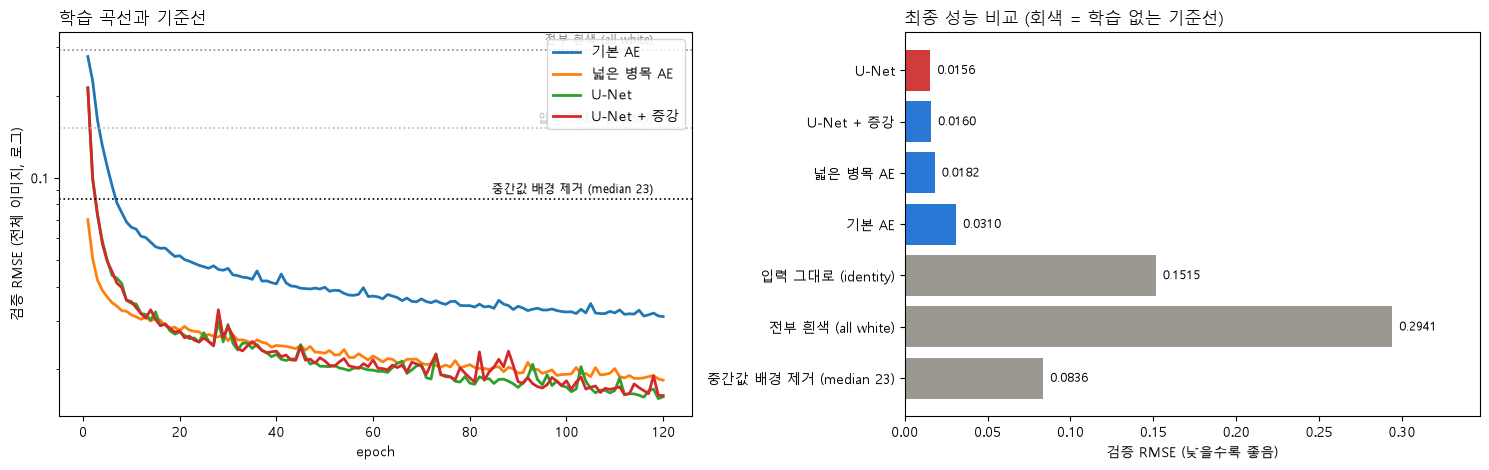

In [11]:
# 왼쪽: 학습 곡선과 기준선
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1.1, 1]})  # 곡선이 잘 보이도록 왼쪽 칸을 조금 넓게
for name, hist in histories.items():  # 모델 4종의 학습 과정을 겹쳐 보기 위해
    axes[0].plot(hist["epoch"], hist["val_rmse"], linewidth=2, label=name)  # epoch별 검증 RMSE를 그리기 위해
for (bname, s), color in zip(baseline_scores.items(), ["#bbb", "#888", "black"]):  # 기준선 3종을 함께 보이기 위해
    axes[0].axhline(s["RMSE"], color=color, linestyle=":", linewidth=1.2)  # 기준선 RMSE를 점선으로 표시하기 위해
    axes[0].text(118, s["RMSE"] * 1.05, bname, fontsize=8.5, color=color, ha="right")  # 점선이 어떤 기준선인지 알리기 위해
plain_log(axes[0])  # 0.3 ~ 0.015 범위를 한 그래프에 담기 위해
axes[0].set_xlabel("epoch")  # 가로축 의미를 알리기 위해
axes[0].set_ylabel("검증 RMSE (전체 이미지, 로그)")  # 세로축 의미를 알리기 위해
axes[0].set_title("학습 곡선과 기준선", loc="left")  # 왼쪽 그래프 내용을 알리기 위해
axes[0].legend(loc="upper right")  # 모델별 선을 구분하기 위해

# 오른쪽: 기준선 + 모델 최종 RMSE 막대
order = results["RMSE"].sort_values(ascending=False)  # 나쁜 모델 → 좋은 모델 순서로 쌓기 위해
labels = list(baseline_scores)[::-1] + list(order.index)  # 기준선을 아래, 최고 모델을 맨 위에 두기 위해
values = [baseline_scores[k]["RMSE"] for k in list(baseline_scores)[::-1]] + list(order.values)  # 라벨과 같은 순서로 막대 길이를 맞추기 위해
colors = [GRAY] * 3 + [BLUE] * (len(order) - 1) + [RED]  # 기준선 회색 · 모델 파랑 · 최고 빨강으로 구분하기 위해
bars = axes[1].barh(labels, values, color=colors)  # 가로 막대로 비교하기 위해
for bar, v in zip(bars, values):  # 막대마다 값을 적기 위해
    axes[1].text(v + 0.004, bar.get_y() + bar.get_height() / 2, f"{v:.4f}", va="center", fontsize=9)  # 막대 끝에 RMSE를 보이기 위해
axes[1].set_xlabel("검증 RMSE (낮을수록 좋음)")  # 읽는 방향을 알리기 위해
axes[1].set_title("최종 성능 비교 (회색 = 학습 없는 기준선)", loc="left")  # 색의 의미를 알리기 위해
axes[1].set_xlim(0, max(values) * 1.18)  # 값 글자가 잘리지 않도록
plt.tight_layout()  # 여백을 자동으로 맞추기 위해
plt.show()  # 그림을 출력하기 위해

**결과 해설**

```
왼쪽 학습 곡선 : 네 모델 모두 처음 몇 epoch 만에 중간값 기준선(검은 점선) 아래로 하강, 120 epoch까지 완만하게 계속 감소
오른쪽 막대    : 기준선 0.2941 · 0.1515 · 0.0836 → 모델 0.0310 · 0.0182 · 0.0160 · 0.0156(U-Net)
```

- 모든 모델이 학습 없는 기준선보다 좋음 → **오토인코더가 실제로 복원 방법을 학습**
- 곡선이 끝까지 내려가는 중 → 1-5의 "아직 수렴 전" 한계와 일치

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| plain_log() | 사용자 정의 함수 | 로그 축 + 일반 숫자 눈금 | `plain_log(axes[0])` |
| sort_values() | pandas.Series | RMSE 큰 순서 정렬 | `results["RMSE"].sort_values(ascending=False)` |
| plot() · axhline() · text() · barh() | matplotlib | 곡선 · 점선 · 글자 · 가로 막대 | `axes[1].barh(labels, values, color=colors)` |
| get_y() · get_height() | matplotlib.patches | 막대 위치 · 높이 | `bar.get_y() + bar.get_height() / 2` |
| [::-1] · 리스트 + · * | Python 기본 문법 | 순서 뒤집기 · 이어 붙이기 · 반복 | `[GRAY] * 3 + [BLUE] * ... + [RED]` |

### 1-7. 가장 어려운 검증 이미지 복원 결과

**한글 요약**

- 최고 모델로 검증 29장의 **복원 전 · 후 PSNR** 계산 → 모든 이미지가 개선되었는지 확인
- 복원 후 PSNR이 가장 낮은(가장 어려운) 이미지를 손상 입력 · 기준선 · 최고 모델 · 정답과 비교

**실행 흐름**

1. **입력**: `results` · `trained` · 검증 29장
2. **처리**: 최고 모델 선택 → 이미지별 복원 전 · 후 PSNR → 가장 어려운 이미지 4칸 비교
3. **저장**: `best_name` · `best_fn` · `per_image` · `x` · `y`
4. **출력**: 개선 여부 · 개선 폭, 4칸 비교 그림

최고 모델: U-Net · 검증 29장 모두 개선: True · 개선 폭 16.3 ~ 22.4 dB


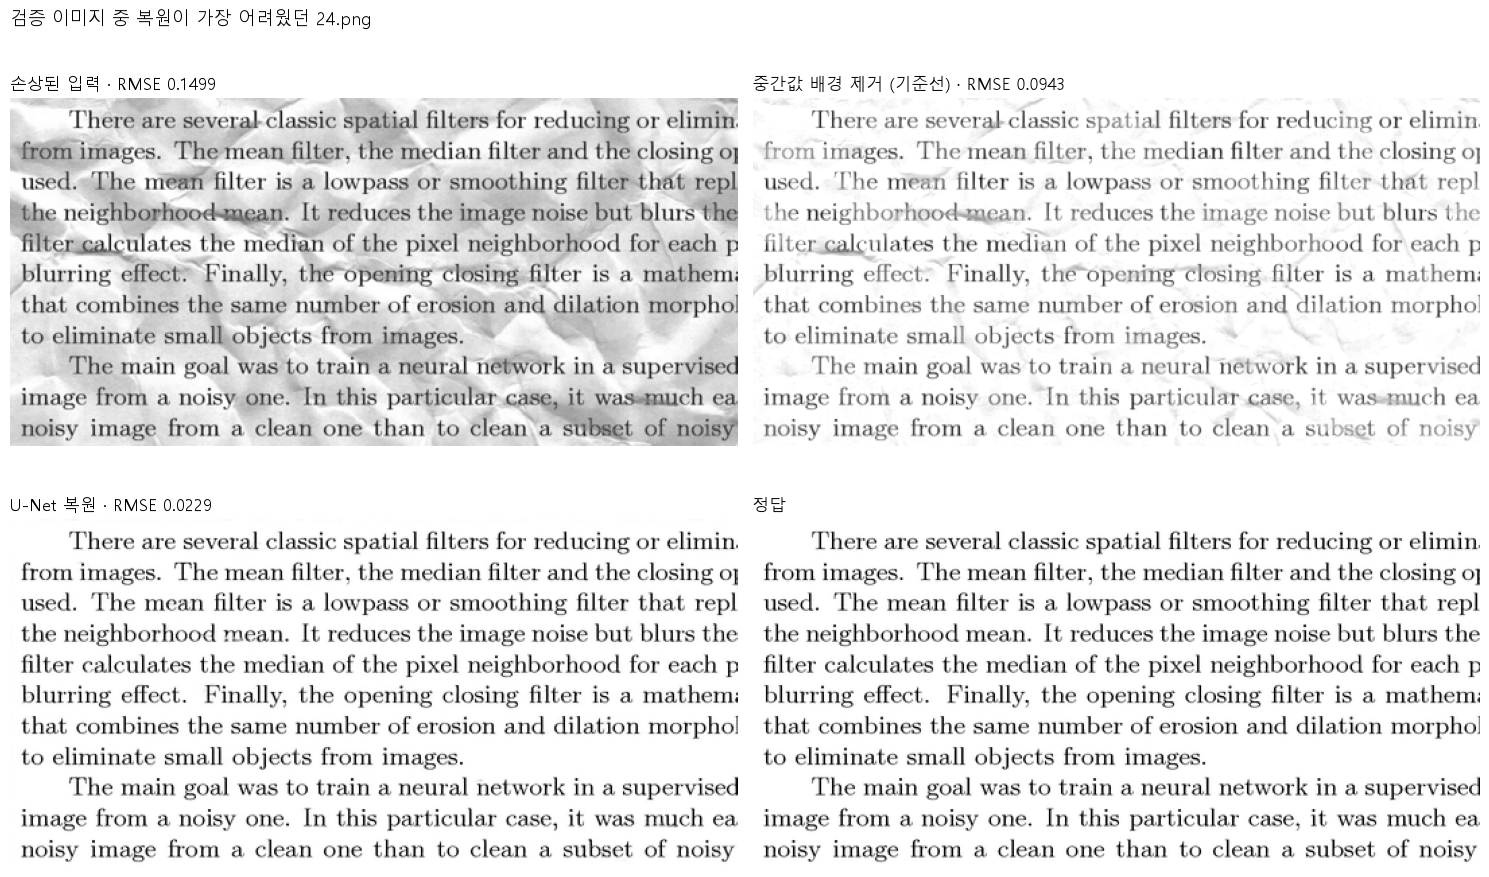

In [12]:
# 최고 모델 · 비교 대상
best_name = results["RMSE"].idxmin()  # 검증 RMSE가 가장 낮은 모델을 고르기 위해
best_fn = full_image_fn(trained[best_name])  # 전체 이미지를 복원하는 함수로 바꾸기 위해
median_fn = BASELINES["중간값 배경 제거 (median 23)"]  # 학습 없는 최선의 기준선과 비교하기 위해

# 검증 이미지별 복원 전 · 후 PSNR
per_image = []  # 이미지별 결과를 모으기 위해
for name in val_files:  # 검증 29장을 모두 확인하기 위해
    x, y = dirty[name].unsqueeze(0).to(device), clean[name].unsqueeze(0).to(device)  # 모델 입력 모양으로 GPU에 올리기 위해
    before = 10 * np.log10(1 / ((x - y) ** 2).mean().item())  # 손상 그대로의 PSNR을 구하기 위해
    after = 10 * np.log10(1 / ((best_fn(x) - y) ** 2).mean().item())  # 복원 후 PSNR을 구하기 위해
    per_image.append({"이미지": name, "복원 전 PSNR": before, "복원 후 PSNR": after, "개선(dB)": after - before})  # 개선 폭까지 함께 기록하기 위해
per_image = pd.DataFrame(per_image).sort_values("복원 후 PSNR")  # 가장 어려운 이미지가 맨 앞에 오도록
print(f"최고 모델: {best_name} · 검증 29장 모두 개선: {(per_image['개선(dB)'] > 0).all()} · "
      f"개선 폭 {per_image['개선(dB)'].min():.1f} ~ {per_image['개선(dB)'].max():.1f} dB")  # 나빠진 이미지가 없는지 · 개선 범위를 확인하기 위해

# 가장 어려운 이미지 4칸 비교
worst = per_image.iloc[0]["이미지"]  # 복원 후 PSNR이 가장 낮은 이미지를 고르기 위해
x, y = dirty[worst].unsqueeze(0).to(device), clean[worst].unsqueeze(0).to(device)  # 1-8에서도 쓸 입력 · 정답을 준비하기 위해
panels = [("손상된 입력", x), ("중간값 배경 제거 (기준선)", median_fn(x)), (f"{best_name} 복원", best_fn(x)), ("정답", y)]  # 네 가지를 같은 순서로 비교하기 위해
fig, axes = plt.subplots(2, 2, figsize=(15, 9.5))  # 2행 2열로 크게 보기 위해
for ax, (title, img) in zip(axes.ravel(), panels):  # 칸과 이미지를 짝지어 그리기 위해
    rmse = ((img - y) ** 2).mean().sqrt().item()  # 칸마다 정답과의 오차를 보이기 위해
    ax.imshow(img.squeeze().cpu(), cmap="gray", vmin=0, vmax=1)  # GPU 텐서를 CPU로 옮겨 흑백으로 보이기 위해
    ax.set_title(f"{title}" + ("" if title == "정답" else f" · RMSE {rmse:.4f}"), loc="left")  # 정답 칸에는 RMSE를 빼기 위해
    ax.axis("off")  # 문서만 보이도록 눈금 숨김
fig.suptitle(f"검증 이미지 중 복원이 가장 어려웠던 {worst}", x=0.01, ha="left", fontsize=13)  # 어떤 이미지인지 알리기 위해
plt.tight_layout()  # 여백을 자동으로 맞추기 위해
plt.show()  # 그림을 출력하기 위해

**결과 해설**

```
검증 29장 모두 개선: True : 복원 후 PSNR이 낮아진 이미지 없음
개선 폭 16.3 ~ 22.4 dB    : 가장 어려운 이미지도 16 dB 이상 개선
24.png RMSE               : 입력 0.1499 → 기준선 0.0943 → U-Net 0.0229
4칸 비교                  : 기준선은 구김 자국이 흐리게 남고, U-Net은 정답에 가까운 흰 배경
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| full_image_fn() | 사용자 정의 함수 | 최고 모델 전체 이미지 복원 | `full_image_fn(trained[best_name])` |
| idxmin() · all() · min() · max() | pandas.Series | 최고 모델 · 전부 참 · 범위 | `(per_image['개선(dB)'] > 0).all()` |
| sort_values() · iloc[] | pandas.DataFrame | PSNR 낮은 순 · 첫 행 | `per_image.iloc[0]["이미지"]` |
| mean() · sqrt() · cpu() | torch.Tensor | RMSE 계산 · CPU 이동 | `((img - y) ** 2).mean().sqrt().item()` |
| subplots() · suptitle() · ravel() | matplotlib · numpy | 2 × 2 칸 · 전체 제목 · 칸 펼치기 | `fig.suptitle(...)` |
| 조건 표현식 | Python 기본 문법 | 정답 칸만 RMSE 생략 | `"" if title == "정답" else ...` |

### 1-8. 글자 부분 확대 · test 이미지 복원

**한글 요약**

- 가장 어려운 이미지의 글자 부분을 확대해 입력 · 복원 · 정답과 **|복원 − 정답| 오차 지도** 비교 → 남은 오차 위치 확인
- 정답이 없는 test 이미지 2장에 최고 모델 적용 → 처음 보는 문서에서도 복원되는지 확인

**실행 흐름**

1. **입력**: 1-7의 `x` · `y` · `best_fn`, test 앞 2장
2. **처리**: 글자 영역 자르기 → 입력 · 복원 · 정답 확대 → 픽셀별 절대 오차 지도 → test 2장 복원
3. **저장**: `err`
4. **출력**: 확대 비교 · 오차 지도, test 복원 그림

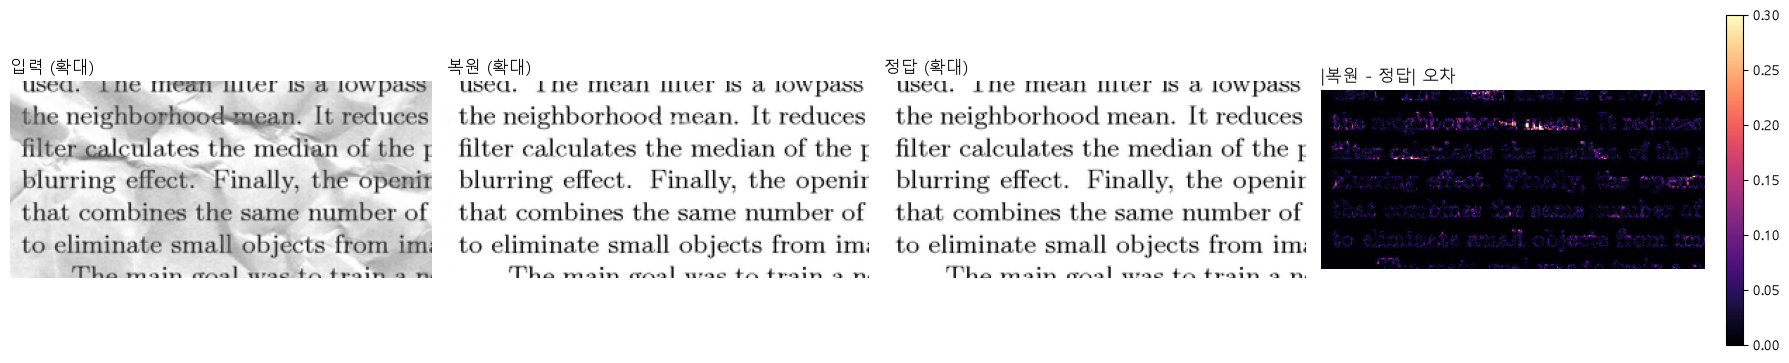

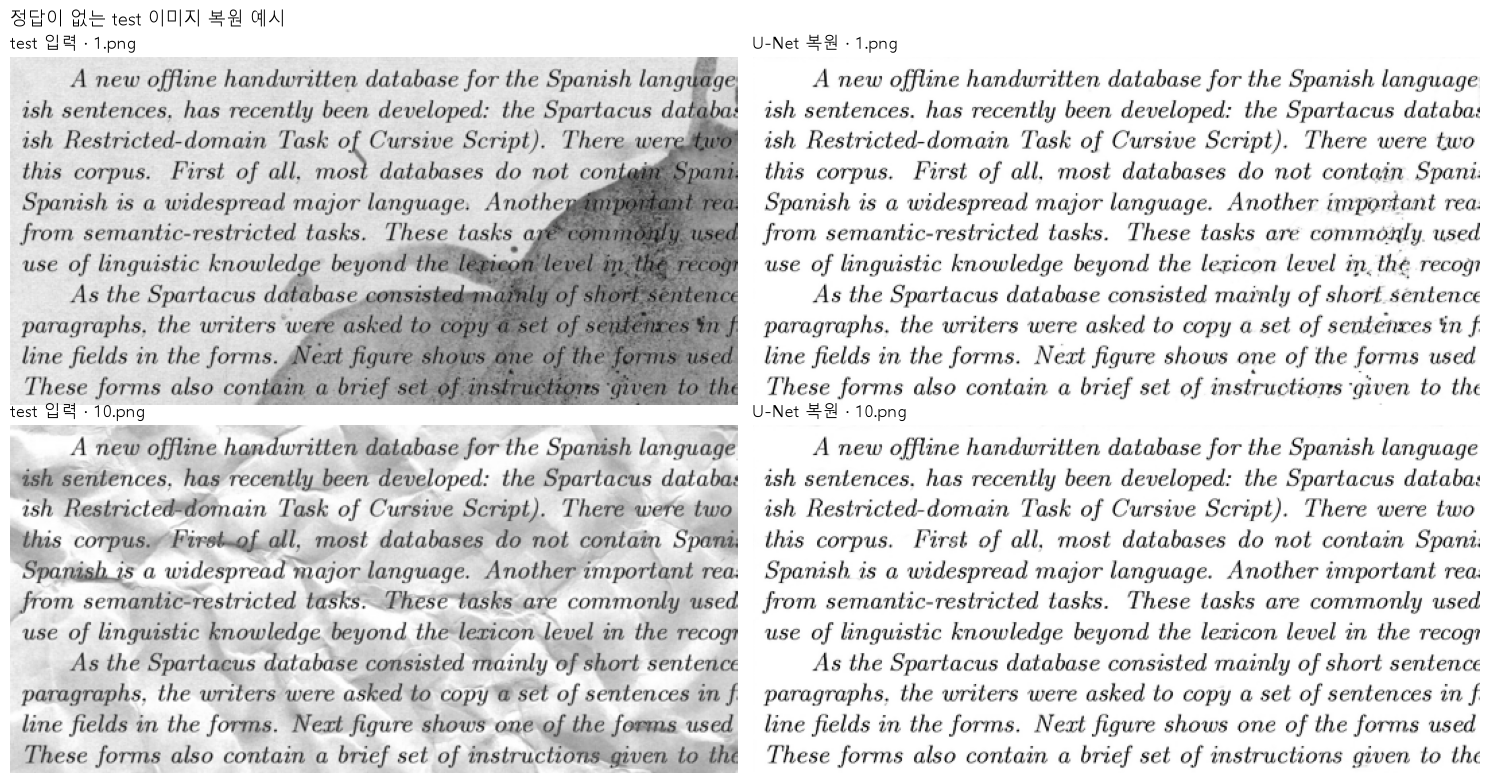

In [13]:
# 글자 부분 확대와 오차 지도
crop = (slice(60, 200), slice(0, 300))  # 글자가 모인 세로 60~200 · 가로 0~300을 확대하기 위해
fig, axes = plt.subplots(1, 4, figsize=(18, 3.6))  # 입력 · 복원 · 정답 · 오차를 한 줄에 보기 위해
err = (best_fn(x) - y).abs().squeeze().cpu()  # 어디에 오차가 남았는지 픽셀별로 보기 위해
for ax, (title, img) in zip(axes, [("입력", x.squeeze().cpu()), ("복원", best_fn(x).squeeze().cpu()), ("정답", y.squeeze().cpu())]):  # 앞 3칸을 같은 방식으로 그리기 위해
    ax.imshow(img[crop], cmap="gray", vmin=0, vmax=1)  # 같은 영역을 같은 밝기 기준으로 비교하기 위해
    ax.set_title(f"{title} (확대)", loc="left")  # 칸 내용을 알리기 위해
    ax.axis("off")  # 글자만 보이도록 눈금 숨김
im = axes[3].imshow(err[crop], cmap="magma", vmin=0, vmax=0.3)  # 오차가 클수록 밝게 보이도록
axes[3].set_title("|복원 - 정답| 오차", loc="left")  # 오차 지도임을 알리기 위해
axes[3].axis("off")  # 오차 지도만 보이도록 눈금 숨김
fig.colorbar(im, ax=axes[3], fraction=0.04)  # 색이 어떤 오차 크기인지 읽기 위해
plt.tight_layout()  # 여백을 자동으로 맞추기 위해
plt.show()  # 그림을 출력하기 위해

# test 이미지 복원
fig, axes = plt.subplots(2, 2, figsize=(15, 8))  # 2장 × (입력, 복원)을 나란히 보기 위해
for row, name in enumerate(list(test_imgs)[:2]):  # 정답 없는 test 앞 2장을 보기 위해
    xt = test_imgs[name].unsqueeze(0).to(device)  # 모델 입력 모양으로 GPU에 올리기 위해
    for col, (title, img) in enumerate([("test 입력", xt), (f"{best_name} 복원", best_fn(xt))]):  # 왼쪽 입력 · 오른쪽 복원으로 배치하기 위해
        axes[row, col].imshow(img.squeeze().cpu(), cmap="gray", vmin=0, vmax=1)  # 같은 밝기 기준으로 보이기 위해
        axes[row, col].set_title(f"{title} · {name}", loc="left")  # 어떤 이미지인지 알리기 위해
        axes[row, col].axis("off")  # 문서만 보이도록 눈금 숨김
fig.suptitle("정답이 없는 test 이미지 복원 예시", x=0.01, ha="left", fontsize=13)  # 정답이 없는 사례임을 알리기 위해
plt.tight_layout()  # 여백을 자동으로 맞추기 위해
plt.show()  # 그림을 출력하기 위해

**결과 해설**

```
확대 비교 : 배경 얼룩은 거의 사라지고 글자 모양 유지
오차 지도 : 남은 오차가 대부분 글자 경계에 집중
test 복원 : 처음 보는 문서의 커피 얼룩 · 구김도 대부분 제거, 진한 얼룩이 글자와 겹친 곳에만 작은 점이 남음
```

- 글자 경계 오차 원인: 글자 가장자리의 회색 픽셀(안티앨리어싱)을 정확히 맞히기 어려움

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| abs() · squeeze() · cpu() | torch.Tensor | 절대 오차 · 차원 제거 · CPU 이동 | `(best_fn(x) - y).abs().squeeze().cpu()` |
| imshow() · colorbar() · suptitle() | matplotlib | 이미지 · 색 막대 · 전체 제목 | `fig.colorbar(im, ax=axes[3], fraction=0.04)` |
| slice() · list() · enumerate() | Python 내장 함수 | 자를 범위 · 목록 · 번호 반복 | `slice(60, 200)` · `enumerate(list(test_imgs)[:2])` |
| 튜플 인덱싱 | Python 기본 문법 | 영역 자르기 | `img[crop]` |

---
## 2. 심전도 이상 탐지

**정상 신호만으로 오토인코더를 학습**하면 모델은 정상 패턴만 잘 복원. 처음 보는 이상 신호는 제대로 복원하지 못하므로 **복원 오차가 크면 이상**으로 판정.

### 2-1. 데이터 분할과 신호 확인

**한글 요약**

임계값을 정하는 데이터와 최종 평가 데이터를 분리해 **평가 점수가 부풀려지지 않게** 분할.

- **오토인코더 학습 · 검증**: 정상 신호의 70% (라벨은 쓰지 않음, 정상만)
- **임계값 보정**: 나머지 정상 + 모든 이상 신호의 50%
- **최종 평가**: 나머지 50% (임계값 결정에 전혀 쓰지 않음)

<img src="images/m5_ecgsplit.png" alt="심전도 4,998개의 학습 · 검증 · 보정 · 평가 분할" width="837">

**실행 흐름**

1. **입력**: ECG5000 CSV (없으면 내려받아 `ecg.csv`로 저장)
2. **처리**: 신호 · 이상 여부 분리 → 정상 70% AE용 / 나머지 보정 · 평가 반반 → 학습 데이터 기준 0~1 정규화
3. **저장**: `signals` · `is_anomaly` · `ae_train` · `ae_val` · `calib_idx` · `test_idx` · `norm`
4. **출력**: 용도별 개수 표, 정상 · 이상 신호 그래프

,정상,이상
AE 학습,1736,0
AE 검증,307,0
임계값 보정,438,1039
최종 평가,438,1040


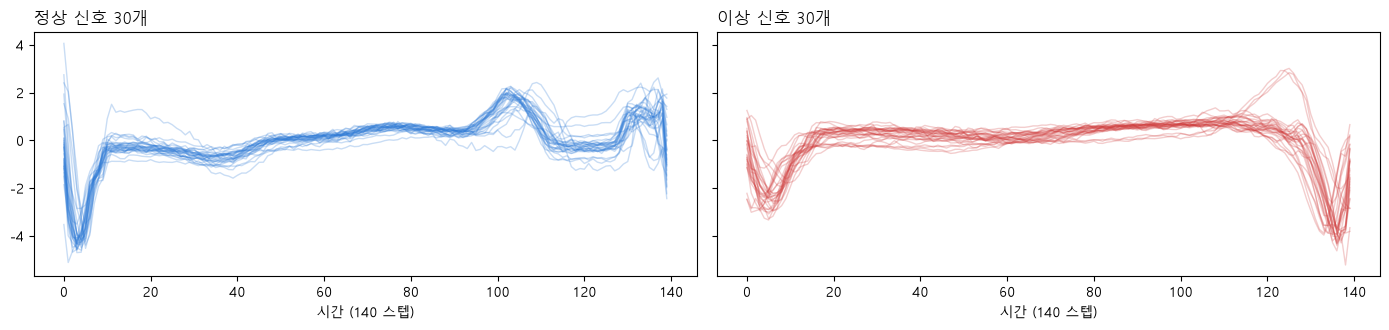

In [14]:
# 데이터 불러오기
ecg_path = Path("ecg.csv")  # 내려받은 파일을 다시 쓰기 위해 저장 위치 지정
if not ecg_path.exists():  # 처음 실행할 때만 내려받기 위해
    pd.read_csv("http://storage.googleapis.com/download.tensorflow.org/data/ecg.csv", header=None).to_csv(ecg_path, header=False, index=False)  # 다음 실행부터 인터넷 없이 쓰도록 저장
ecg = pd.read_csv(ecg_path, header=None)  # 4998행 × 141열을 읽기 위해
signals = ecg.iloc[:, :-1].to_numpy(np.float32)  # 모델 입력으로 쓸 신호 (4998, 140)
is_anomaly = (ecg.iloc[:, -1].to_numpy() == 0).astype(int)  # 마지막 열 0 = 이상이므로 이상을 1로 표시하기 위해

# 용도별 분할
normal_idx, anomaly_idx = np.flatnonzero(is_anomaly == 0), np.flatnonzero(is_anomaly == 1)  # 정상 · 이상 위치를 나누기 위해
ae_idx, rest_normal = train_test_split(normal_idx, train_size=0.7, random_state=SEED)  # 오토인코더는 정상 70%로만 학습하기 위해
ae_train, ae_val = train_test_split(ae_idx, test_size=0.15, random_state=SEED)  # 조기 종료에 쓸 정상 검증 데이터를 떼어 두기 위해
pool = np.concatenate([rest_normal, anomaly_idx])  # 보정 · 평가에 쓸 나머지 정상 + 모든 이상을 모으기 위해
calib_idx, test_idx = train_test_split(pool, test_size=0.5, stratify=is_anomaly[pool], random_state=SEED)  # 임계값을 정한 데이터로 평가하지 않도록 이상 비율을 유지해 반반

# 정규화
lo, hi = signals[ae_train].min(), signals[ae_train].max()  # 정보 누수를 막기 위해 학습 데이터에서만 기준을 정함
norm = lambda idx: (signals[idx] - lo) / (hi - lo)  # 모든 신호를 같은 기준으로 0~1 범위에 맞추기 위해

# 분할 확인
assert len(set(ae_train) | set(ae_val) | set(calib_idx) | set(test_idx)) == len(signals)  # 4개 용도가 겹침 없이 전체를 나누는지 확인하기 위해
split_table = pd.DataFrame({
    "정상": [len(ae_train), len(ae_val), (is_anomaly[calib_idx] == 0).sum(), (is_anomaly[test_idx] == 0).sum()],  # 용도별 정상 개수를 보기 위해
    "이상": [0, 0, is_anomaly[calib_idx].sum(), is_anomaly[test_idx].sum()],  # AE 학습에 이상이 없음을 보이기 위해
}, index=["AE 학습", "AE 검증", "임계값 보정", "최종 평가"])  # 용도 이름을 행 이름으로 보기 위해
display(split_table)  # 분할 결과를 표로 확인하기 위해

# 정상 · 이상 신호 비교
fig, axes = plt.subplots(1, 2, figsize=(14, 3.4), sharey=True)  # 세로 축을 공유해 크기를 비교하기 위해
for ax, idx, title, color in [(axes[0], normal_idx[:30], "정상 신호 30개", BLUE), (axes[1], anomaly_idx[:30], "이상 신호 30개", RED)]:  # 정상 · 이상을 30개씩 비교하기 위해
    for s in signals[idx]:  # 신호를 하나씩 겹쳐 그리기 위해
        ax.plot(s, color=color, alpha=0.25, linewidth=1)  # 반투명으로 겹쳐 공통 모양을 보기 위해
    ax.set_title(title, loc="left")  # 칸 내용을 알리기 위해
    ax.set_xlabel("시간 (140 스텝)")  # 가로축 의미를 알리기 위해
plt.tight_layout()  # 여백을 자동으로 맞추기 위해
plt.show()  # 그림을 출력하기 위해

**결과 해설**

```
AE 학습 1,736 · 검증 307 : 정상 신호만 사용 (라벨 없이 학습)
임계값 보정 438 + 1,039  : 정상 + 이상, 임계값 결정에만 사용
최종 평가 438 + 1,040    : 임계값 결정에 쓰지 않은 데이터로 최종 성능 확인
assert 통과              : 4개 용도가 겹침 없이 전체 4,998개를 나눔
```

- 정상 신호: 시작 직후 깊은 하강 + 100 스텝 근처 봉우리
- 이상 신호: 시작 하강이 얕고, 100 스텝 봉우리 없이 끝부분(130 스텝 이후)에 깊은 하강
- 정상 패턴만 배운 모델은 이런 다른 모양을 잘 복원하지 못함 → 복원 오차로 구분

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| Path() · exists() | pathlib | 파일 존재 확인 | `Path("ecg.csv").exists()` |
| read_csv() · iloc[] · to_csv() · DataFrame() | pandas | CSV 읽기 · 열 선택 · 저장 · 개수 표 | `ecg.iloc[:, :-1]` |
| flatnonzero() · concatenate() | numpy | 조건 위치 · 배열 잇기 | `np.flatnonzero(is_anomaly == 0)` |
| train_test_split() | sklearn.model_selection | 용도별 분할, 이상 비율 유지 | `train_test_split(pool, test_size=0.5, stratify=...)` |
| display() · subplots(sharey) | IPython · matplotlib | 표 출력 · 세로 축 공유 | `plt.subplots(1, 2, ..., sharey=True)` |
| lambda · set 합집합 \| · assert | Python 기본 문법 | 정규화 함수 · 인덱스 합치기 · 검증 | <code>set(ae_train) &#124; set(ae_val) &#124; ...</code> |

### 2-2. LSTM · GRU 오토인코더 · 모델과 오차 함수

**한글 요약**

인코더 RNN이 140 스텝 신호를 **마지막 은닉 상태 하나로 요약** → 140번 반복해 디코더 RNN에 입력 → 신호 복원. 신호별 평균 제곱 오차를 이상 점수로 사용.

<img src="images/m5_rnnae.png" alt="순환 오토인코더의 요약과 복원 순서" width="837">

**실행 흐름**

1. **입력**: 정규화한 신호 (N, 140, 1)
2. **처리**: 인코더 RNN → 마지막 은닉 상태 → 140번 반복 → 디코더 RNN → 선형층
3. **저장**: `RNNAutoencoder` · `to_tensor` · `recon_error`
4. **출력**: 없음 (정의 셀)

In [15]:
# RNN 오토인코더
class RNNAutoencoder(nn.Module):  # LSTM · GRU를 같은 구조로 비교하기 위해
    """인코더 RNN의 마지막 은닉 상태(신호 요약)를 140번 반복해 디코더 RNN에 넣고 신호 복원"""
    def __init__(self, cell="lstm", hidden=64, layers=1, seq_len=140):  # 셀 종류 · 층 수를 바꿔 실험하기 위해
        super().__init__()  # nn.Module 기본 설정을 먼저 실행하기 위해
        rnn = nn.LSTM if cell == "lstm" else nn.GRU  # 같은 구조에서 셀 종류만 바꾸기 위해
        self.seq_len = seq_len  # 복원할 길이를 기억하기 위해
        self.encoder = rnn(1, hidden, num_layers=layers, batch_first=True)  # 스텝당 값 1개를 은닉 64로 요약하기 위해
        self.decoder = rnn(hidden, hidden, num_layers=layers, batch_first=True)  # 요약 벡터에서 스텝별 은닉을 만들기 위해
        self.head = nn.Linear(hidden, 1)  # 은닉 64를 신호 값 1개로 되돌리기 위해
    def forward(self, x):  # model(x)로 호출할 때 실행되도록 (x: (B, 140, 1))
        _, h = self.encoder(x)  # 신호 전체를 요약한 마지막 은닉 상태만 쓰기 위해
        z = (h[0] if isinstance(h, tuple) else h)[-1]  # LSTM은 (h, c) 튜플이라 h를 꺼내고 마지막 층만 쓰기 위해 (B, hidden)
        out, _ = self.decoder(z.unsqueeze(1).repeat(1, self.seq_len, 1))  # 요약을 140 스텝 반복 입력해 순서대로 복원하기 위해
        return self.head(out)  # (B, 140, 1) 신호로 되돌리기 위해

# 신호 → 텐서 변환 · 복원 오차 함수
def to_tensor(idx):  # 여러 곳에서 같은 변환을 쓰기 위해
    return torch.tensor(norm(idx)).unsqueeze(-1)  # 정규화 후 RNN 입력 모양 (N, 140, 1)로 바꾸기 위해
@torch.no_grad()  # 평가에는 기울기가 필요 없으므로
def recon_error(model, idx):  # 신호별 이상 점수를 구하기 위해
    model.eval()  # 추론 모드로 바꾸기 위해
    x = to_tensor(idx).to(device)  # GPU에서 계산하기 위해
    return ((model(x) - x) ** 2).mean(dim=(1, 2)).cpu().numpy()  # 신호별 평균 제곱 오차를 이상 점수로 쓰기 위해

**결과 해설**

```
출력 없음 : 순환 오토인코더 · 텐서 변환 · 복원 오차 함수 정의, 다음 셀에서 두 구조 학습
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| RNNAutoencoder · to_tensor() · recon_error() | 사용자 정의 클래스 · 함수 | 순환 오토인코더 · 텐서 변환 · 복원 오차 | `recon_error(model, ae_val)` |
| LSTM · GRU · Linear | torch.nn | 순환 셀 2종 · 은닉 → 값 | `nn.LSTM if cell == "lstm" else nn.GRU` |
| unsqueeze() · repeat() · mean(dim) | torch.Tensor | 차원 추가 · 140번 반복 · 신호별 평균 | `z.unsqueeze(1).repeat(1, self.seq_len, 1)` |
| tensor() · no_grad() | torch | 배열 → 텐서 · 기울기 끄기 | `torch.tensor(norm(idx))` |
| isinstance() · 조건 표현식 | Python 내장 함수 · 기본 문법 | LSTM 튜플 구분 · 셀 선택 | `h[0] if isinstance(h, tuple) else h` |

### 2-2. LSTM · GRU 오토인코더 · 학습

**한글 요약**

LSTM(1층) · GRU(2층) 두 구조를 정상 신호만으로 학습, 정상 검증 신호의 평균 복원 오차가 20 epoch 동안 나아지지 않으면 조기 종료.

**실행 흐름**

1. **입력**: 정상 학습 신호 `ae_train` · 정상 검증 신호 `ae_val`
2. **처리**: AdamW 학습 → epoch마다 정상 검증 오차 → 최고 가중치 저장 · 조기 종료 → 두 구조 학습
3. **저장**: `rnn_models` · `rnn_hist`
4. **출력**: 구조별 최저 검증 오차 · 학습 epoch 수

In [16]:
# 학습 함수
def train_rnn_ae(model, epochs=150, patience=20):  # 두 구조를 같은 조건으로 학습하기 위해
    seed_all()  # 모델마다 같은 난수 조건에서 시작하기 위해
    model = model.to(device)  # GPU에서 학습하기 위해
    loader = DataLoader(TensorDataset(to_tensor(ae_train)), batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(SEED))  # 정상 신호만 128개씩 섞되 순서를 재현하기 위해
    optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)  # 가중치 감쇠로 과적합을 줄이기 위해
    best, best_state, wait, hist = float("inf"), None, 0, []  # 최고 오차 · 최고 가중치 · 정체 epoch 수 · 기록을 준비하기 위해
    for epoch in range(epochs):  # 최대 150 epoch까지 학습하기 위해
        model.train()  # 학습 모드로 바꾸기 위해
        for (xb,) in loader:  # 입력 = 정답(자기 자신 복원)이라 텐서 하나만 꺼내기 위해
            xb = xb.to(device)  # GPU에서 계산하기 위해
            optimizer.zero_grad()  # 이전 기울기가 섞이지 않도록
            F.mse_loss(model(xb), xb).backward()  # 자기 자신을 복원하는 오차의 기울기를 구하기 위해
            optimizer.step()  # 가중치를 갱신하기 위해
        val = recon_error(model, ae_val).mean()  # 조기 종료 기준으로 정상 검증 신호의 평균 복원 오차를 보기 위해
        hist.append(val)  # 학습 과정을 기록하기 위해
        if val < best:  # 최고 기록이 나오면 저장하기 위해
            best, best_state, wait = val, copy.deepcopy(model.state_dict()), 0  # 이후 학습이 덮어써도 보존되도록 복사하고 정체 수 초기화
        else:
            wait += 1  # 개선 없는 epoch 수를 세기 위해
            if wait >= patience:  # 20 epoch 연속 개선이 없으면
                break  # 시간을 아끼기 위해 조기 종료
    model.load_state_dict(best_state)  # 최고 시점 가중치로 평가하기 위해
    return model, hist  # 모델과 학습 기록을 함께 돌려주기 위해

# LSTM · GRU 학습
rnn_models, rnn_hist = {}, {}  # 2-3 · 2-4에서 다시 쓰기 위해 결과를 모음
for name, kwargs in {"LSTM (1층)": dict(cell="lstm"), "GRU (2층)": dict(cell="gru", layers=2)}.items():  # 두 구조를 같은 반복문으로 학습하기 위해
    rnn_models[name], rnn_hist[name] = train_rnn_ae(RNNAutoencoder(**kwargs))  # 설정을 인자로 펼쳐 모델을 만들고 학습하기 위해
    print(f"{name}: 정상 검증 복원 MSE {min(rnn_hist[name]):.5f} ({len(rnn_hist[name])} epoch)")  # 최저 오차와 학습 epoch 수를 확인하기 위해

LSTM (1층): 정상 검증 복원 MSE 0.00315 (81 epoch)


GRU (2층): 정상 검증 복원 MSE 0.00188 (150 epoch)


**결과 해설**

```
LSTM (1층) 0.00315 (81 epoch) : 81 epoch에서 조기 종료
GRU (2층) 0.00188 (150 epoch) : 최대 epoch까지 개선, 정상 복원 오차가 LSTM의 약 60%
```

- 정상 패턴을 더 정확히 복원할수록 이상 신호와의 오차 차이가 커짐 → GRU가 이상 탐지에 유리할 것으로 예상 (2-3에서 확인)

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| train_rnn_ae() | 사용자 정의 함수 | 조기 종료 포함 학습 | `train_rnn_ae(RNNAutoencoder(**kwargs))` |
| TensorDataset · DataLoader | torch.utils.data | 텐서 → 데이터셋 · 128개씩 공급 | `TensorDataset(to_tensor(ae_train))` |
| optim.AdamW() · mse_loss() | torch | 가중치 감쇠 Adam · 복원 오차 | `torch.optim.AdamW(..., weight_decay=1e-4)` |
| deepcopy() · load_state_dict() | copy · torch | 최고 가중치 복사 · 복원 | `copy.deepcopy(model.state_dict())` |
| dict() · min() · len() | Python 내장 함수 | 설정 묶음 · 최저 오차 · epoch 수 | `dict(cell="gru", layers=2)` |
| ** 펼치기 · for (xb,) in | Python 기본 문법 | 설정 → 인자 · 1개짜리 튜플 꺼내기 | `RNNAutoencoder(**kwargs)` |

### 2-3. 임계값 3종 비교

**한글 요약**

- **평균 + 2σ** (라벨 사용 안 함): 정상 검증 신호 복원 오차의 평균 + 2 × 표준편차
- **95% 분위수** (라벨 사용 안 함): 정상 검증 신호의 95%가 통과하는 오차
- **Youden J** (보정 데이터의 라벨): 보정 데이터에서 (재현율 − 오탐률)이 최대인 오차
- 임계값보다 복원 오차가 크면 이상 판정, 성능은 **최종 평가 데이터**로만 계산

**실행 흐름**

1. **입력**: `rnn_models`, 검증 · 보정 · 평가 신호
2. **처리**: 용도별 복원 오차 → 보정 데이터 ROC로 Youden J → 평균 + 2σ · 95% 분위수 → 평가 데이터 6개 지표
3. **저장**: `ad_table` · `roc_data`
4. **출력**: 모델 × 임계값 방법 결과 표 (최고값 강조)

In [17]:
# 모델 · 임계값 방법별 평가
rows, roc_data = [], {}  # 결과 표와 2-4 그래프용 데이터를 모으기 위해
for name, model in rnn_models.items():  # 두 모델을 같은 방식으로 평가하기 위해
    val_err, calib_err, test_err = recon_error(model, ae_val), recon_error(model, calib_idx), recon_error(model, test_idx)  # 용도별 이상 점수를 구하기 위해
    fpr_c, tpr_c, thr_c = roc_curve(is_anomaly[calib_idx], calib_err)  # 보정 데이터에서 임계값별 오탐률 · 재현율을 구하기 위해
    finite = np.isfinite(thr_c)  # 첫 임계값(무한대)을 빼기 위해
    thresholds = {
        "평균 + 2σ": val_err.mean() + 2 * val_err.std(),  # 라벨 없이 정상 오차 분포의 위쪽 꼬리를 기준으로 쓰기 위해
        "95% 분위수": np.quantile(val_err, 0.95),  # 정상의 5%만 이상으로 판정하도록
        "Youden J (보정 데이터)": thr_c[finite][np.argmax((tpr_c - fpr_c)[finite])],  # 보정 데이터에서 재현율 - 오탐률이 가장 큰 지점을 고르기 위해
    }
    y_true = is_anomaly[test_idx]  # 임계값 결정에 쓰지 않은 데이터로 평가하기 위해
    roc_data[name] = (roc_curve(y_true, test_err), roc_auc_score(y_true, test_err), test_err, thresholds)  # 2-4 그래프에서 다시 계산하지 않도록 저장
    for method, thr in thresholds.items():  # 임계값 3종을 같은 지표로 비교하기 위해
        pred = (test_err > thr).astype(int)  # 임계값을 넘으면 이상으로 판정하기 위해
        rows.append({"모델": name, "임계값 방법": method, "임계값": thr, "ROC-AUC": roc_auc_score(y_true, test_err),
                     "균형 정확도": balanced_accuracy_score(y_true, pred), "이상 정밀도": precision_score(y_true, pred),
                     "이상 재현율": recall_score(y_true, pred), "정상 특이도": recall_score(y_true, pred, pos_label=0),
                     "이상 F1": f1_score(y_true, pred)})  # 임계값과 무관한 AUC와 판정 지표 5개를 함께 보기 위해

# 결과 표
ad_table = pd.DataFrame(rows).set_index(["모델", "임계값 방법"])  # 모델 × 방법 2단 행 이름으로 보기 위해
ad_table.style.format({"임계값": "{:.5f}", **{c: "{:.3f}" for c in ad_table.columns if c != "임계값"}}) \
    .highlight_max(subset=["균형 정확도", "이상 F1"], color="#d4edda")  # 가장 좋은 조합을 초록으로 강조하기 위해

**결과 해설**

```
ROC-AUC GRU 0.959 vs LSTM 0.934    : 정상 복원이 정확한 GRU가 이상을 더 잘 구분
라벨 없는 임계값 (평균 + 2σ · 95%) : 이상 정밀도 0.968 ~ 0.974로 매우 신중, 재현율은 GRU 0.742 ~ 0.789 · LSTM 0.519 ~ 0.661
GRU + Youden J                     : 재현율 0.934 · 특이도 0.902 · F1 0.945 · 균형 정확도 0.918 (최고)
```

- 라벨 없는 임계값: GRU도 이상 신호 4~5개 중 1개를 놓침
- Youden J 임계값은 보정 데이터에서 정하고 **따로 떼어 둔 평가 데이터**에서 측정 → 점수 부풀림 없음

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| recon_error() | 사용자 정의 함수 | 신호별 복원 오차 | `recon_error(model, calib_idx)` |
| roc_curve() · roc_auc_score()<br>precision · recall · f1 · balanced_accuracy | sklearn.metrics | 임계값별 오탐률 · 재현율, AUC<br>판정 지표 (pos_label=0 → 특이도) | `roc_curve(is_anomaly[calib_idx], calib_err)`<br>`recall_score(y_true, pred, pos_label=0)` |
| isfinite() · argmax() · quantile() | numpy | 무한대 제외 · 최댓값 위치 · 분위수 | `np.quantile(val_err, 0.95)` |
| set_index() · style.highlight_max() | pandas | 2단 행 이름 · 최댓값 강조 | `.highlight_max(subset=[...], ...)` |
| 조건 컴프리헨션 · \\ 줄 이어 쓰기 | Python 기본 문법 | 임계값 외 열 서식 · 긴 줄 나누기 | `{c: "{:.3f}" for c in ... if c != "임계값"}` |

### 2-4. ROC 곡선과 복원 오차 분포

**한글 요약**

- 왼쪽: 최종 평가 데이터에서 두 모델의 ROC 곡선 비교
- 오른쪽: AUC가 높은 모델의 정상 · 이상 복원 오차 분포 + 임계값 3종 위치

**실행 흐름**

1. **입력**: 2-3의 `roc_data` · `ad_table`
2. **처리**: ROC-AUC 최고 모델 선택 → 두 모델 ROC 곡선 → 정상 · 이상 오차 히스토그램 + 임계값 점선
3. **저장**: `best_ad` · `test_err` · `thresholds` · `y_true`
4. **출력**: ROC 곡선 · 오차 분포 그래프

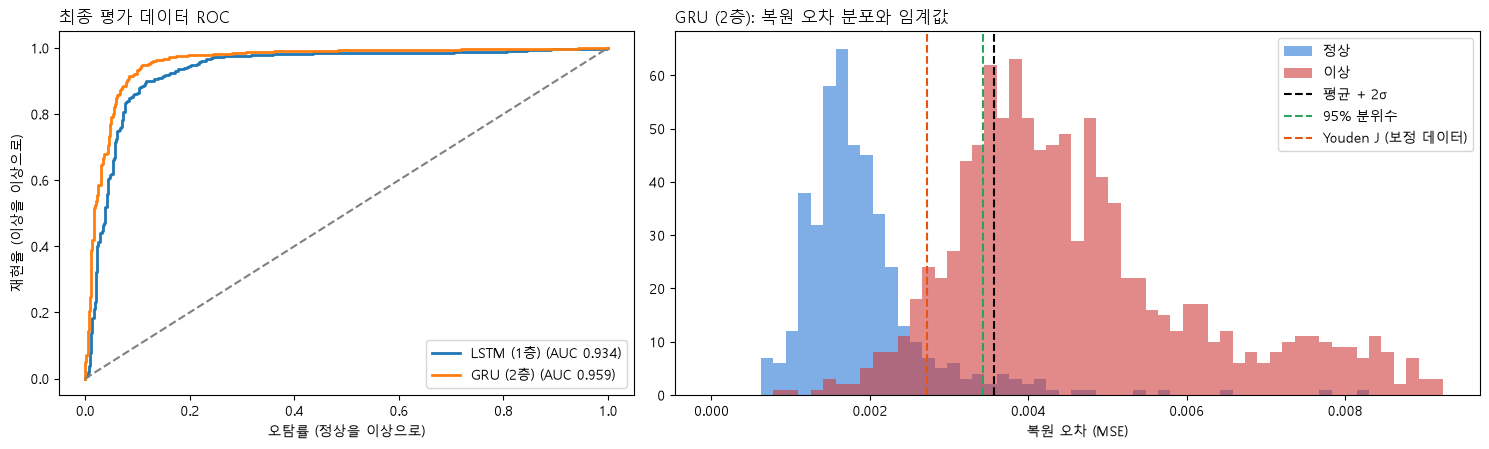

In [18]:
# 최고 모델 선택
best_ad = ad_table["ROC-AUC"].groupby(level=0).first().idxmax()  # AUC는 임계값과 무관하므로 모델별 첫 행으로 비교하기 위해
(fpr, tpr, _), auc, test_err, thresholds = roc_data[best_ad]  # 2-3에서 저장한 값을 다시 계산하지 않고 쓰기 위해
y_true = is_anomaly[test_idx]  # 최종 평가 정답으로 분포를 나누기 위해

# 왼쪽: ROC 곡선
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 1.4]})  # 분포 그래프가 잘 보이도록 오른쪽 칸을 넓게
for name, ((f, t, _), a, _, _) in roc_data.items():  # 두 모델의 ROC를 겹쳐 보기 위해
    axes[0].plot(f, t, linewidth=2, label=f"{name} (AUC {a:.3f})")  # 오탐률 대비 재현율을 그리기 위해
axes[0].plot([0, 1], [0, 1], "--", color="gray")  # 무작위 판정과 비교하기 위해
axes[0].set_xlabel("오탐률 (정상을 이상으로)")  # 가로축 의미를 알리기 위해
axes[0].set_ylabel("재현율 (이상을 이상으로)")  # 세로축 의미를 알리기 위해
axes[0].set_title("최종 평가 데이터 ROC", loc="left")  # 어떤 데이터 기준인지 알리기 위해
axes[0].legend(loc="lower right")  # 모델별 선과 AUC를 구분하기 위해

# 오른쪽: 복원 오차 분포와 임계값
bins = np.linspace(0, np.quantile(test_err, 0.99), 60)  # 극단값 1%를 빼고 60칸으로 나눠 분포가 잘 보이도록
axes[1].hist(test_err[y_true == 0], bins=bins, alpha=0.6, color=BLUE, label="정상")  # 정상 오차 분포를 보기 위해
axes[1].hist(test_err[y_true == 1], bins=bins, alpha=0.6, color=RED, label="이상")  # 이상 오차 분포를 보기 위해
for (method, thr), color in zip(thresholds.items(), ["black", GREEN, "#e6550d"]):  # 임계값 3종 위치를 비교하기 위해
    axes[1].axvline(thr, color=color, linestyle="--", linewidth=1.5, label=method)  # 임계값을 세로 점선으로 표시하기 위해
axes[1].set_xlabel("복원 오차 (MSE)")  # 가로축 의미를 알리기 위해
axes[1].set_title(f"{best_ad}: 복원 오차 분포와 임계값", loc="left")  # 어떤 모델인지 알리기 위해
axes[1].legend()  # 분포 · 임계값을 구분하기 위해
plt.tight_layout()  # 여백을 자동으로 맞추기 위해
plt.show()  # 그림을 출력하기 위해

**결과 해설**

```
ROC 곡선    : GRU(AUC 0.959)가 LSTM(0.934)보다 왼쪽 위에 가까움
오차 분포   : 정상(파랑)은 0.002 근처에 몰리고 이상(빨강)은 오른쪽으로 넓게 퍼짐, 0.002 ~ 0.003 구간에서 일부 겹침
임계값 위치 : Youden J가 가장 왼쪽 → 이상을 더 많이 잡는 대신 정상 일부를 이상으로 판정
```

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| groupby() · first() · idxmax() | pandas | 모델별 첫 행 · AUC 최고 모델 | `ad_table["ROC-AUC"].groupby(level=0).first()` |
| linspace() · quantile() | numpy | 히스토그램 구간 · 99% 분위수 | `np.linspace(0, np.quantile(test_err, 0.99), 60)` |
| plot() · hist() · axvline() · legend() | matplotlib | ROC 곡선 · 히스토그램 · 점선 · 범례 | `axes[1].hist(...)` |
| 튜플 풀기 · _ · for ... in zip() | Python 기본 문법 | 저장한 값 꺼내기 · 안 쓰는 값 · 짝 반복 | `(fpr, tpr, _), auc, test_err, thresholds = roc_data[best_ad]` |

### 2-5. 판정 사례: 원 신호 vs 복원

**한글 요약**

GRU + Youden J 임계값으로 최종 평가 데이터를 판정한 뒤, **정상 → 정상 · 이상 → 이상 · 이상인데 정상(놓침)** 세 집단에서 복원 오차가 중앙값인 대표 사례의 원 신호와 복원 신호 비교.

**실행 흐름**

1. **입력**: 최고 모델 · Youden J 임계값 · 평가 데이터 오차
2. **처리**: 평가 데이터 판정 → 집단 3개 구분 → 집단별 오차 중앙값 사례 → 원 신호 · 복원 · 차이 영역
3. **저장**: `pred_all` · `cases`
4. **출력**: 집단별 대표 사례 그래프

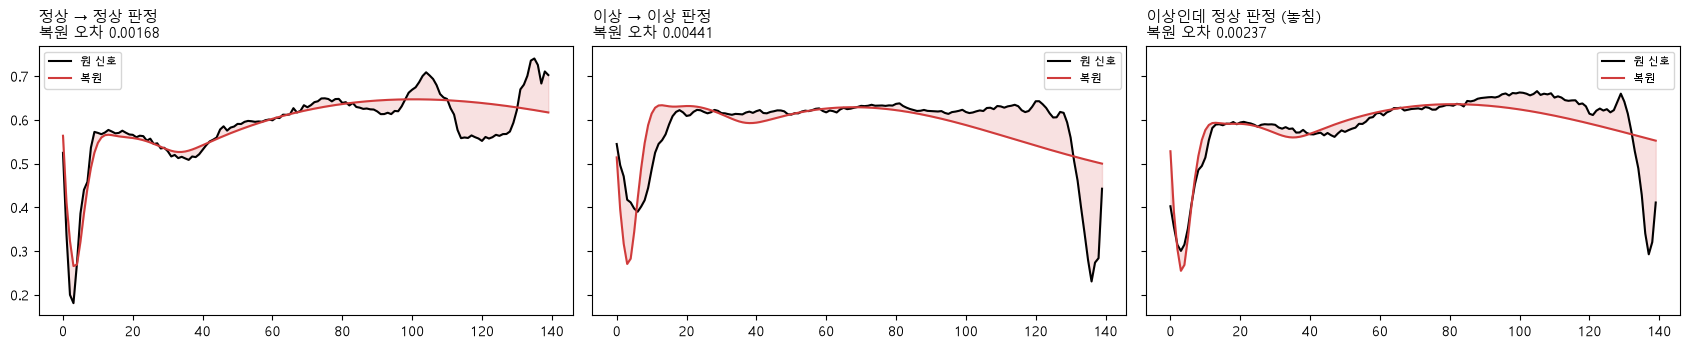

In [19]:
# 판정
model = rnn_models[best_ad]  # 2-4에서 고른 GRU (2층)로 판정하기 위해
thr = thresholds["Youden J (보정 데이터)"]  # 가장 균형이 좋았던 임계값을 쓰기 위해
pred_all = (test_err > thr).astype(int)  # 평가 데이터를 이상(1) · 정상(0)으로 판정하기 위해
cases = [("정상 → 정상 판정", (y_true == 0) & (pred_all == 0)), ("이상 → 이상 판정", (y_true == 1) & (pred_all == 1)),
         ("이상인데 정상 판정 (놓침)", (y_true == 1) & (pred_all == 0))]  # 맞힌 경우와 놓친 경우를 나눠 보기 위해

# 집단별 대표 사례
fig, axes = plt.subplots(1, 3, figsize=(17, 3.6), sharey=True)  # 세 집단을 같은 세로 축으로 비교하기 위해
for ax, (title, mask) in zip(axes, cases):  # 집단마다 한 칸씩 그리기 위해
    i = test_idx[mask][np.argsort(test_err[mask])[len(test_err[mask]) // 2]]  # 극단 사례가 아닌 대표 사례를 보기 위해 오차 중앙값 선택
    x = to_tensor([i]).to(device)  # 모델 입력 모양 (1, 140, 1)로 만들기 위해
    with torch.no_grad():  # 추론만 하므로 기울기를 끄기 위해
        r = model(x).squeeze().cpu().numpy()  # 복원 신호를 그래프용 배열로 바꾸기 위해
    s = x.squeeze().cpu().numpy()  # 원 신호를 그래프용 배열로 바꾸기 위해
    ax.plot(s, color="black", linewidth=1.5, label="원 신호")  # 원 신호를 그리기 위해
    ax.plot(r, color=RED, linewidth=1.5, label="복원")  # 복원 신호를 겹쳐 그리기 위해
    ax.fill_between(range(140), s, r, color=RED, alpha=0.15)  # 어디서 복원이 어긋났는지 차이 영역을 칠하기 위해
    ax.set_title(f"{title}\n복원 오차 {np.mean((s - r) ** 2):.5f}", loc="left", fontsize=10.5)  # 사례의 복원 오차를 함께 보이기 위해
    ax.legend(fontsize=8)  # 두 선을 구분하기 위해
plt.tight_layout()  # 여백을 자동으로 맞추기 위해
plt.show()  # 그림을 출력하기 위해

**결과 해설**

```
정상 → 정상 판정 (0.00168) : 전체 흐름은 맞히고 봉우리만 매끄럽게 복원
이상 → 이상 판정 (0.00441) : 끝부분의 깊은 하강을 복원하지 못해 차이가 큼
놓친 사례 (0.00237)        : 대부분 구간이 정상과 비슷하고 끝부분만 달라 임계값(0.00273)보다 오차가 작음
```

- 오토인코더는 신호를 매끄럽게 복원하는 경향(병목에 의한 저역 통과 효과) → 짧은 이상 구간은 복원 오차에 작게 반영

**소속별 최종 요약표**

| 함수·문법 | 소속 | 역할 | 코드에서 사용한 위치 |
| :-- | :-- | :-- | :-- |
| to_tensor() | 사용자 정의 함수 | 신호 1개 → (1, 140, 1) 텐서 | `to_tensor([i])` |
| no_grad() · squeeze() · cpu() · numpy() | torch | 추론 · 차원 제거 · 배열 변환 | `model(x).squeeze().cpu().numpy()` |
| argsort() · mean() · astype() | numpy | 오차 순서 · 사례 오차 · 1/0 변환 | `np.argsort(test_err[mask])` |
| plot() · fill_between() · subplots(sharey) | matplotlib | 신호 곡선 · 차이 영역 · 세로 축 공유 | `ax.fill_between(range(140), s, r, ...)` |
| & · with · // | Python 기본 문법 | 두 조건 동시 · 블록 안 기울기 끄기 · 중앙 위치 | `(y_true == 1) & (pred_all == 0)` |

---
## 3. 마무리

### 핵심 결과

| 파트 | 최고 모델 | 결과 | 비교 대상 |
| :-- | :-- | :-- | :-- |
| **문서 복원** | U-Net | 검증 RMSE **0.0156** · PSNR 36.20 dB | 중간값 배경 제거 기준선 0.0836 → **5.4배** 개선 |
| **이상 탐지** | GRU (2층) + Youden J | ROC-AUC **0.959** · 재현율 0.934 · 특이도 0.902 · F1 0.945 | LSTM (1층) ROC-AUC 0.934 |

- **문서 복원**: 병목 채널 확장(0.0310 → 0.0182)과 스킵 연결(→ 0.0156)이 성능 향상의 두 열쇠, 증강은 효과 없음
- **이상 탐지**: 정상 패턴을 더 정확히 복원하는 모델일수록 이상과의 오차 차이가 커져 구분력 상승

### 실무 제안

- 이상을 놓치는 비용이 크면 **소량의 라벨로 임계값 보정** (Youden J)
- 라벨이 전혀 없으면 **분위수 방식으로 시작** → 오탐 비용과 놓침 비용을 비교하며 조정

### 한계

- 문서 복원: 네 모델 모두 120 epoch 안에 수렴하지 않음 → 더 오래 학습하면 개선 여지
- 증강 효과 판단: 검증 이미지 29장뿐이라 0.0004 차이는 구분하기 어려움
- 이상 탐지: 일부 구간만 다른 이상 신호는 복원 오차가 작아 놓치기 쉬움

### 최종 요약표

| 단계 | 한 일 | 핵심 근거 |
| :-- | :-- | :-- |
| **1-1 ~ 1-3. 데이터 · 기준선** | 크기 비율 유지 분할, 학습 없는 기준선 3종 | 중간값 배경 제거 0.0836 |
| **1-4 ~ 1-6. 모델 비교** | 기본 AE · 넓은 병목 AE · U-Net · U-Net + 증강, 같은 조건 학습 | U-Net 0.0156 (5.4배 개선) |
| **1-7 ~ 1-8. 복원 확인** | 가장 어려운 이미지 · 오차 지도 · test 복원 | 29장 모두 개선, 16.3 ~ 22.4 dB |
| **2-1 ~ 2-2. 이상 탐지 학습** | 정상만 학습한 LSTM · GRU 오토인코더 | GRU 정상 복원 오차 0.00188 |
| **2-3 ~ 2-5. 임계값 · 사례** | 임계값 3종, 평가 데이터로만 측정 | GRU + Youden J F1 0.945 |